# 0. download from TA's Google Drive

## my download or upload

In [2]:
from google.colab import drive

In [ ]:
!gdown --id '19CzXudqN58R3D-1G8KeFWk8UDQwlb8is' --output food-11.zip
#https://drive.google.com/uc?id=19CzXudqN58R3D-1G8KeFWk8UDQwlb8is

#https://drive.google.com/file/d/1EB5q0UCS9qEO-C26y0TPkehwyaNjAWmx/view?usp=sharing #複製了一份在讀書會資料夾

Permission denied: https://drive.google.com/uc?id=19CzXudqN58R3D-1G8KeFWk8UDQwlb8is
Maybe you need to change permission over 'Anyone with the link'?


In [11]:
# 在左手邊 資料夾 去 mount GoogleDrive 的讀書會資料夾
!ls -l "drive/My Drive/Machine Learning(李宏毅)/"
!cp "drive/My Drive/Machine Learning(李宏毅)/food-11.zip" ./
!ls -l ./

total 1136120
-rw------- 1 root root     132437 Sep 20 03:08 'Copy of hw1_regression.ipynb'
-rw------- 1 root root     211118 Oct 12 01:16 'Copy of hw2_classification.ipynb'
-rw------- 1 root root      12742 Oct 12 01:17 'Copy of UserDefinedTrainingProcedure.ipynb'
-rw------- 1 root root 1163028761 Oct 30 11:58  food-11.zip
-rw------- 1 root root        151 Oct 23 09:43  Schedule.gdoc
total 1135788
drwx------ 4 root root       4096 Oct 30 12:36 drive
drwxr-xr-x 4 root root       4096 Oct 30 11:44 food-11_fortf
-rw------- 1 root root 1163028761 Oct 30 12:42 food-11.zip
drwxr-xr-x 1 root root       4096 Oct 28 16:30 sample_data
-rw-r--r-- 1 root root          0 Oct 30 11:44 tmp.log


In [14]:
!md5sum food-11.zip

4365d46d7cb8ff8a28530570053d119c  food-11.zip


In [12]:
from google.colab import files

#uploaded = files.upload()

#for fn in uploaded.keys():
#  print('User uploaded file "{name}" with length {length} bytes'.format(name=fn, length=len(uploaded[fn])))
  
#files.download('food-11.zip')

## download

In [13]:
# 下載資料集
#別再重複下載大型檔案 會影響到學校流量
#!ls food-11.zip | wc -l | awk '{if($1==1) {print "food-11.zip is exist";} else {print "to download gdown --id 19CzXudqN58R3D-1G8KeFWk8UDQwlb8is --output food-11.zip";}}' | awk -F "to download " '{if(NF>1) system($2)}'
# 解壓縮
!ls -l food-11/*/*.jpg | wc -l | awk '{if($0!=16643) system("unzip food-11.zip")}'

Streaming output truncated to the last 5000 lines.
  inflating: food-11/training/4_165.jpg  
  inflating: food-11/training/5_376.jpg  
  inflating: food-11/training/2_691.jpg  
  inflating: food-11/training/0_541.jpg  
  inflating: food-11/training/3_482.jpg  
  inflating: food-11/training/0_227.jpg  
  inflating: food-11/training/5_410.jpg  
  inflating: food-11/training/4_603.jpg  
  inflating: food-11/training/8_341.jpg  
  inflating: food-11/training/5_1154.jpg  
  inflating: food-11/training/9_37.jpg  
  inflating: food-11/training/9_152.jpg  
  inflating: food-11/training/5_438.jpg  
  inflating: food-11/training/9_1287.jpg  
  inflating: food-11/training/8_369.jpg  
  inflating: food-11/training/2_1455.jpg  
  inflating: food-11/training/10_247.jpg  
  inflating: food-11/training/7_32.jpg  
  inflating: food-11/training/10_521.jpg  
  inflating: food-11/training/2_1333.jpg  
  inflating: food-11/training/2_861.jpg  
  inflating: food-11/training/0_569.jpg  
  inflating: food-11/

# 1. Imports

In [15]:
import tensorflow as tf
tf.executing_eagerly() #check

True

In [16]:
import os
import numpy as np
import cv2
import pandas as pd
import time

from google.colab.patches import cv2_imshow

#2. Read image

##2.1 tf.keras.preprocessing.image_dataset_from_directory

In [17]:
!mkdir food-11_fortf
!mkdir food-11_fortf/training
!mkdir food-11_fortf/validation

#for labels='inferred'
!ls food-11/training/*.jpg | awk -F '/' '{print $NF}' | awk -F '_' '{print $1}' | sort | uniq | awk '{print "mkdir food-11_fortf/training/"$1}' | awk '{system($0)}'
!ls food-11/training/*.jpg | awk -F '/' '{print $NF}' | awk -F [_.] '{label=$1; ithfile=$2; filename=$0; tmpstr = sprintf("cp food-11/training/%s food-11_fortf/training/%s/%s_%04d.jpg", filename, label, label, ithfile); print tmpstr;}' | awk '{system($0)}'

#for labels={a list/tuple of integer labels of the same size as the number of image files found in the directory}
#!ls food-11/training/*.jpg | awk -F '/' '{print $NF}' | awk -F [_.] '{label=$1; ithfile=$2; filename=$0; tmpstr = sprintf("cp food-11/training/%s food-11_fortf/training/%02d_%04d.jpg", filename, label, ithfile); print tmpstr;}' | awk '{system($0)}' >> tmp.log 2>&1

mkdir: cannot create directory ‘food-11_fortf’: File exists
mkdir: cannot create directory ‘food-11_fortf/training’: File exists
mkdir: cannot create directory ‘food-11_fortf/validation’: File exists


In [18]:
#for labels='inferred'
!ls food-11/validation/*.jpg | awk -F '/' '{print $NF}' | awk -F '_' '{print $1}' | sort | uniq | awk '{print "mkdir food-11_fortf/validation/"$1}' | awk '{system($0)}' >> tmp.log 2>&1
!ls food-11/validation/*.jpg | awk -F '/' '{print $NF}' | awk -F [_.] '{label=$1; ithfile=$2; filename=$0; tmpstr = sprintf("cp food-11/validation/%s food-11_fortf/validation/%s/%s_%04d.jpg", filename, label, label, ithfile); print tmpstr;}' | awk '{system($0)}' >> tmp.log 2>&1

#for labels={a list/tuple of integer labels of the same size as the number of image files found in the directory}
#!ls food-11/validation/*.jpg | awk -F '/' '{print $NF}' | awk -F [_.] '{label=$1; ithfile=$2; filename=$0; tmpstr = sprintf("cp food-11/validation/%s food-11_fortf/validation/%02d_%04d.jpg", filename, label, ithfile); print tmpstr;}' | awk '{system($0)}' >> tmp.log 2>&1

In [19]:
train_img_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    directory="food-11_fortf/training", labels='inferred', label_mode='int', class_names=["0", "1", "2" ,"3", "4", "5", "6", "7", "8", "9", "10"],
    color_mode='rgb', batch_size=1, image_size=(128, 128), shuffle=False, seed=12345,
    validation_split=None, subset=None, interpolation='nearest', follow_links=False
)

Found 9866 files belonging to 11 classes.


In [20]:
preprocessing_data_augmentation = tf.keras.Sequential(
    [
     tf.keras.layers.experimental.preprocessing.RandomFlip("horizontal_and_vertical"),
     tf.keras.layers.experimental.preprocessing.RandomRotation(0.041667, interpolation="nearest") #15/360 * 2pi
    ]
)

train_img_dataset_2 = train_img_dataset.map(lambda x,y: (preprocessing_data_augmentation(x), y))

In [21]:
valid_img_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    directory="food-11_fortf/validation", labels='inferred', label_mode='int', class_names=["0", "1", "2" ,"3", "4", "5", "6", "7", "8", "9", "10"],
    color_mode='rgb', batch_size=1, image_size=(128, 128), shuffle=False, seed=12345,
    validation_split=None, subset=None, interpolation='nearest', follow_links=False
)

Found 3430 files belonging to 11 classes.


#### details: slow while training

In [ ]:
train_batch_size = 128
learner = Learner(11, train_dataset=train_img_dataset, valid_dataset=valid_img_dataset)
learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.99, epsilon=1e-09)

learner.num_epochs = 5
learner.num_epochs_validation = 1
learner.train()

Epoch 1 24.98 sec(s) , Loss: 285.837585, CategoricalAccurancy:0.189236, Valid Loss: 0.000000, Valid CategoricalAccurancy:0.000000
Epoch 2 23.58 sec(s) , Loss: 1.968258, CategoricalAccurancy:0.339246, Valid Loss: 0.000000, Valid CategoricalAccurancy:0.000000
Epoch 3 23.43 sec(s) , Loss: 1.836271, CategoricalAccurancy:0.371579, Valid Loss: 0.000000, Valid CategoricalAccurancy:0.000000
Epoch 4 23.73 sec(s) , Loss: 1.748761, CategoricalAccurancy:0.404926, Valid Loss: 0.000000, Valid CategoricalAccurancy:0.000000
Epoch 5 23.52 sec(s) , Loss: 19691.339844, CategoricalAccurancy:0.151125, Valid Loss: 0.000000, Valid CategoricalAccurancy:0.000000


##2.2 Try IO : tf.dataset(numpy.array)

In [22]:
train_img_dataset.cardinality().numpy()

9866

In [23]:
def read_tfdataset(dataset, b_withlabel=True):
  len_dataset = dataset.cardinality().numpy()
  x = np.zeros((len_dataset, 128, 128, 3), dtype=np.uint8)
  y = np.zeros(len_dataset, dtype=np.uint8)
  for idx, data_i in enumerate(dataset):
    if b_withlabel:
      data_i_x, data_i_y = data_i
      y[idx] = data_i_y
    else:
      data_i_x = data_i
    x[idx, :, :] = data_i_x
      
  if b_withlabel:
    return x, y
  else:
    return x

In [24]:
print("Reading data")
train_x, train_y = read_tfdataset(train_img_dataset, True)
print("Size of training data = {}".format(len(train_x)))
val_x, val_y = read_tfdataset(valid_img_dataset, True)
print("Size of validation data = {}".format(len(val_x)))

Reading data
Size of training data = 9866
Size of validation data = 3430


In [ ]:
train2_x, train2_y = read_tfdataset(train_img_dataset_2, True)
print("Size of training data = {}".format(len(train2_x)))

Size of training data = 9866


#### details: sample

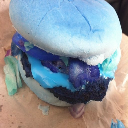

In [ ]:
train_x[123]

cv2_imshow(train_x[123])

##2.X OpenCV (cv2)
利用 OpenCV (cv2) 讀入照片並存放在 numpy array 中

#### details: image data

-rwxr-xr-x 1 root root 40146 Oct 24  2019 ./food-11/training/2_627.jpg
<class 'numpy.ndarray'>
shape= (512, 382, 3)


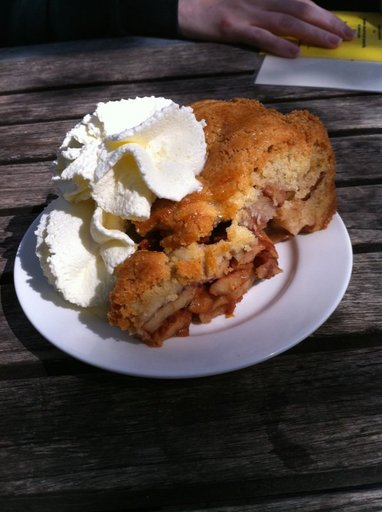

In [ ]:
!ls -l ./food-11/training/2_627.jpg

tmp_img = cv2.imread("./food-11/training/2_627.jpg")
print(type(tmp_img))
print("shape=",tmp_img.shape)

cv2_imshow(tmp_img)

In [ ]:
def Print_CenterImgData(inpimg, pixel_dx=10, pixel_dy=10, width_textpixel=10):
  if not isinstance(tmp_img, np.ndarray):
    return None
  inpshape = inpimg.shape
  if not (isinstance(inpshape, tuple) and len(inpshape)==3):
    return None
  
  y_mid = int(inpshape[0]/2)
  x_mid = int(inpshape[1]/2)
  str_fmt = "%{}s ;".format(width_textpixel)

  for iy in range(y_mid-pixel_dy, y_mid+pixel_dy):
    tmpstr = ""
    for ix in range(x_mid-pixel_dx, x_mid+pixel_dx):
      tmpstr += str_fmt % str((iy, ix)) + str(inpimg[iy][ix])
    print(tmpstr)

def Print_CenterTensorData(inptensor, pixel_dx=10, pixel_dy=10, width_textpixel=10):
  if not isinstance(inptensor, torch.Tensor):
    return None
  inpshape = inptensor.shape
  if not (isinstance(inpshape, tuple) and len(inpshape)==3):
    return None
  
  y_mid = int(inpshape[1]/2)
  x_mid = int(inpshape[2]/2)
  str_fmt = "%{}s ;".format(width_textpixel)

  for iy in range(y_mid-pixel_dy, y_mid+pixel_dy):
    tmpstr = ""
    for ix in range(x_mid-pixel_dx, x_mid+pixel_dx):
      tmpstr += str_fmt % str((iy, ix)) + ','.join([str(inptensor[0][iy][ix]), str(inptensor[1][iy][ix]), str(inptensor[2][iy][ix])])
    print(tmpstr)  

In [ ]:
Print_CenterImgData(tmp_img, 15, 15, 7)

(241, 176) ;[ 3 37 97](241, 177) ;[  3  39 103](241, 178) ;[ 0 34 98](241, 179) ;[  7  42 108](241, 180) ;[ 30  67 135](241, 181) ;[ 33  72 141](241, 182) ;[ 25  64 133](241, 183) ;[ 25  67 138](241, 184) ;[ 24  67 140](241, 185) ;[  6  51 125](241, 186) ;[  0  40 117](241, 187) ;[  0  42 120](241, 188) ;[ 10  59 139](241, 189) ;[ 13  66 146](241, 190) ;[  7  60 140](241, 191) ;[ 13  69 148](241, 192) ;[ 18  76 151](241, 193) ;[ 32  90 162](241, 194) ;[ 41  97 168](241, 195) ;[ 29  81 148](241, 196) ;[  6  52 116](241, 197) ;[ 0 16 78](241, 198) ;[ 0 28 87](241, 199) ;[ 0 29 84](241, 200) ;[ 7 31 85](241, 201) ;[ 9 30 82](241, 202) ;[ 35  52 103](241, 203) ;[33 46 98](241, 204) ;[22 33 85](241, 205) ;[13 21 74]
(242, 176) ;[ 4 38 98](242, 177) ;[ 0 35 98](242, 178) ;[ 0 33 96](242, 179) ;[  5  41 105](242, 180) ;[ 27  63 127](242, 181) ;[ 41  79 144](242, 182) ;[ 37  76 144](242, 183) ;[ 25  66 135](242, 184) ;[ 33  75 146](242, 185) ;[ 25  70 143](242, 186) ;[  6  53 127](242, 187) ;[

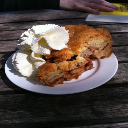

In [ ]:
tmp_img_resized = cv2.resize(tmp_img,(128, 128))
cv2_imshow(tmp_img_resized)

In [ ]:
Print_CenterImgData(tmp_img_resized, 15, 15, 7)

(49, 49) ;[ 63 102 126](49, 50) ;[ 26  78 109](49, 51) ;[26 64 95](49, 52) ;[21 38 59](49, 53) ;[ 84  92 107](49, 54) ;[ 87  89 106](49, 55) ;[138 139 157](49, 56) ;[194 195 214](49, 57) ;[204 204 218](49, 58) ;[220 221 233](49, 59) ;[250 246 244](49, 60) ;[224 231 253](49, 61) ;[ 72  95 139](49, 62) ;[ 65 103 164](49, 63) ;[ 45  86 166](49, 64) ;[ 27  84 172](49, 65) ;[ 15  79 170](49, 66) ;[ 17  85 178](49, 67) ;[ 23  97 189](49, 68) ;[ 25 103 193](49, 69) ;[ 24 103 188](49, 70) ;[ 37 110 188](49, 71) ;[ 11  79 161](49, 72) ;[ 12  76 162](49, 73) ;[ 13  75 168](49, 74) ;[ 15  76 171](49, 75) ;[  2  78 170](49, 76) ;[ 21  96 179](49, 77) ;[ 64 137 208](49, 78) ;[ 78 147 208]
(50, 49) ;[171 186 204](50, 50) ;[ 63  90 119](50, 51) ;[23 45 79](50, 52) ;[ 4 16 47](50, 53) ;[ 5 18 48](50, 54) ;[ 2 23 57](50, 55) ;[ 4 25 61](50, 56) ;[ 4 25 63](50, 57) ;[ 1 20 57](50, 58) ;[12 34 68](50, 59) ;[ 62  85 126](50, 60) ;[ 28  60 125](50, 61) ;[ 24  67 147](50, 62) ;[ 29  76 158](50, 63) ;[ 48  9

In [ ]:
def readfile(path, label):
    # label 是一個 boolean variable，代表需不需要回傳 y 值
    image_dir = sorted(os.listdir(path))
    x = np.zeros((len(image_dir), 128, 128, 3), dtype=np.uint8)
    y = np.zeros((len(image_dir)), dtype=np.uint8)
    for i, file in enumerate(image_dir):
        img = cv2.imread(os.path.join(path, file))
        x[i, :, :] = cv2.resize(img,(128, 128))
        if label:
          y[i] = int(file.split("_")[0])
    if label:
      return x, y
    else:
      return x

In [ ]:
# 分別將 training set、validation set、testing set 用 readfile 函式讀進來
workspace_dir = './food-11'
print("Reading data")
cv_train_x, cv_train_y = readfile(os.path.join(workspace_dir, "training"), True)
print("Size of training data = {}".format(len(cv_train_x)))
cv_val_x, cv_val_y = readfile(os.path.join(workspace_dir, "validation"), True)
print("Size of validation data = {}".format(len(cv_val_x)))
cv_test_x = readfile(os.path.join(workspace_dir, "testing"), False)
print("Size of Testing data = {}".format(len(cv_test_x)))

Reading data
Size of training data = 9866
Size of validation data = 3430
Size of Testing data = 3347


#3. TF Dataset

In [25]:
class MkTFDataset(object):
    def __init__(self):
        self.size_fulltraindata = None
        self.train_dataset = None
        self.valid_dataset = None

    def init_fulltraindata(self, arr_x, arr_y, batch_size=128, ratio=0.8):
        self.batch_size = batch_size
        self.size_fulltraindata = len(arr_x)
        self.fulltrain_dataset = tf.data.Dataset.from_tensor_slices((arr_x, arr_y))
        self.train_dataset = None
        self.valid_dataset = None
        self.fulltrain_dataset_prime = None
        self.Split(batch_size, ratio)

    def Split(self, batch_size=128, ratio=0.8):
        train_size = int(ratio * self.size_fulltraindata)
        self.train_dataset = self.fulltrain_dataset.take(train_size)
        self.train_dataset = self.train_dataset.shuffle(train_size, seed=14522).batch(batch_size)
        self.valid_dataset = self.fulltrain_dataset.skip(train_size).batch(1)
        self.fulltrain_dataset_prime = self.fulltrain_dataset.batch(1)

    def set_validation_dataset(self, arr_x, arr_y):
        self.valid_dataset = None
        self.valid_dataset = tf.data.Dataset.from_tensor_slices((arr_x, arr_y)).batch(1)

    def set_training_dataset(self, arr_x, arr_y, batch_size=128):
        train_size = len(arr_x)
        self.batch_size = batch_size
        self.train_dataset = None
        self.train_dataset = tf.data.Dataset.from_tensor_slices((arr_x, arr_y)) # 後面不能當 spark 亂接, 要記得檢查產出的內容
        self.train_dataset = self.train_dataset.take(train_size)
        self.train_dataset = self.train_dataset.shuffle(train_size, seed=834121).batch(batch_size)


In [26]:
mkdataset = MkTFDataset()

mkdataset.set_training_dataset(train_x, train_y, batch_size=64)
mkdataset.set_validation_dataset(val_x, val_y)

#4. Model

##4.1 test proto-type model

* tutorial

In [ ]:
demo_model = tf.keras.models.Sequential()

demo_model.add(tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)))
demo_model.add(tf.keras.layers.MaxPooling2D((2, 2)))
demo_model.add(tf.keras.layers.Conv2D(64, (3, 3), activation='relu'))
demo_model.add(tf.keras.layers.MaxPooling2D((2, 2)))
demo_model.add(tf.keras.layers.Conv2D(64, (3, 3), activation='relu'))
demo_model.add(tf.keras.layers.Flatten())
demo_model.add(tf.keras.layers.Dense(units=64, activation='relu'))
demo_model.add(tf.keras.layers.Dense(units=11))

In [ ]:
demo_model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 126, 126, 32)      896       
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 63, 63, 32)        0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 61, 61, 64)        18496     
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 30, 30, 64)        0         
_________________________________________________________________
conv2d_2 (Conv2D)            (None, 28, 28, 64)        36928     
_________________________________________________________________
flatten (Flatten)            (None, 50176)             0         
_________________________________________________________________
dense (Dense)                (None, 64)                3

In [ ]:
demo_model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
demo_model.fit(
    x=train_x, y=train_y, batch_size=128, epochs=5, verbose=1, callbacks=None,
    validation_split=0.0, validation_data=None, shuffle=True, class_weight=None,
    sample_weight=None, initial_epoch=0, steps_per_epoch=None,
    validation_steps=None, validation_batch_size=1, validation_freq=0,
    max_queue_size=8, workers=1, use_multiprocessing=False
)

Epoch 1/5
78/78 [==============================] - 2s 28ms/step - loss: 12.4207 - accuracy: 0.1622
Epoch 2/5
78/78 [==============================] - 2s 27ms/step - loss: 2.1708 - accuracy: 0.2390
Epoch 3/5
78/78 [==============================] - 2s 27ms/step - loss: 1.9712 - accuracy: 0.3142
Epoch 4/5
78/78 [==============================] - 2s 27ms/step - loss: 1.7001 - accuracy: 0.4127
Epoch 5/5
78/78 [==============================] - 2s 27ms/step - loss: 1.3503 - accuracy: 0.5408


* model structure from homework

In [ ]:
model_basic = tf.keras.models.Sequential()

model_basic.add(tf.keras.layers.Conv2D(64, (3, 3), strides=(1, 1), padding='same', activation='relu', input_shape=(128, 128, 3)))
model_basic.add(tf.keras.layers.BatchNormalization(axis=3))
model_basic.add(tf.keras.layers.MaxPooling2D((2, 2), strides=(2,2), padding="same"))
model_basic.add(tf.keras.layers.Conv2D(128, (3, 3), strides=(1, 1), padding='same', activation='relu'))
model_basic.add(tf.keras.layers.BatchNormalization(axis=3))
model_basic.add(tf.keras.layers.MaxPooling2D((2, 2), strides=(2,2), padding="same"))
model_basic.add(tf.keras.layers.Conv2D(256, (3, 3), strides=(1, 1), padding='same', activation='relu'))
model_basic.add(tf.keras.layers.BatchNormalization(axis=3))
model_basic.add(tf.keras.layers.MaxPooling2D((2, 2), strides=(2,2), padding="same"))
model_basic.add(tf.keras.layers.Conv2D(512, (3, 3), strides=(1, 1), padding='same', activation='relu'))
model_basic.add(tf.keras.layers.BatchNormalization(axis=3))
model_basic.add(tf.keras.layers.MaxPooling2D((2, 2), strides=(2,2), padding="same"))
model_basic.add(tf.keras.layers.Conv2D(512, (3, 3), strides=(1, 1), padding='same', activation='relu'))
model_basic.add(tf.keras.layers.BatchNormalization(axis=3))
model_basic.add(tf.keras.layers.MaxPooling2D((2, 2), strides=(2,2), padding="same"))
model_basic.add(tf.keras.layers.Flatten())
model_basic.add(tf.keras.layers.Dense(units=1024, activation='relu'))
model_basic.add(tf.keras.layers.Dense(units=512, activation='relu'))
model_basic.add(tf.keras.layers.Dense(units=11, activation='linear'))

In [ ]:
model_basic.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_3 (Conv2D)            (None, 128, 128, 64)      1792      
_________________________________________________________________
batch_normalization (BatchNo (None, 128, 128, 64)      256       
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 64, 64, 64)        0         
_________________________________________________________________
conv2d_4 (Conv2D)            (None, 64, 64, 128)       73856     
_________________________________________________________________
batch_normalization_1 (Batch (None, 64, 64, 128)       512       
_________________________________________________________________
max_pooling2d_3 (MaxPooling2 (None, 32, 32, 128)       0         
_________________________________________________________________
conv2d_5 (Conv2D)            (None, 32, 32, 256)      

In [ ]:
model_basic.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
model_basic.fit(
    x=train_x, y=train_y, batch_size=128, epochs=5, verbose=1, callbacks=None,
    validation_split=0.0, validation_data=(val_x, val_y), shuffle=True, class_weight=None,
    sample_weight=None, initial_epoch=0, steps_per_epoch=None,
    validation_steps=None, validation_batch_size=1, validation_freq=1,
    max_queue_size=8, workers=1, use_multiprocessing=False
)

Epoch 1/5
78/78 [==============================] - 15s 187ms/step - loss: 2.8995 - accuracy: 0.2622 - val_loss: 4.2641 - val_accuracy: 0.0764
Epoch 2/5
78/78 [==============================] - 14s 183ms/step - loss: 1.7752 - accuracy: 0.3966 - val_loss: 2.0650 - val_accuracy: 0.2936
Epoch 3/5
78/78 [==============================] - 14s 183ms/step - loss: 1.5932 - accuracy: 0.4551 - val_loss: 1.7632 - val_accuracy: 0.3898
Epoch 4/5
78/78 [==============================] - 14s 184ms/step - loss: 1.4364 - accuracy: 0.5060 - val_loss: 1.9555 - val_accuracy: 0.4015
Epoch 5/5
78/78 [==============================] - 15s 187ms/step - loss: 1.2851 - accuracy: 0.5518 - val_loss: 1.8224 - val_accuracy: 0.4251


In [ ]:
tf_train_x = tf.constant(train_x, dtype="uint8")
tf_train_y = tf.constant(train_y, dtype="uint8")

In [ ]:
model_basic.fit(
    x=tf_train_x, y=tf_train_y, batch_size=128, epochs=5, verbose=1, callbacks=None,
    validation_split=0.0, validation_data=None, shuffle=True, class_weight=None,
    sample_weight=None, initial_epoch=0, steps_per_epoch=None,
    validation_steps=None, validation_batch_size=1, validation_freq=0,
    max_queue_size=8, workers=1, use_multiprocessing=False
)

Epoch 1/5
78/78 [==============================] - 8s 96ms/step - loss: 1.1406 - accuracy: 0.6079
Epoch 2/5
78/78 [==============================] - 8s 97ms/step - loss: 0.9759 - accuracy: 0.6662
Epoch 3/5
78/78 [==============================] - 8s 96ms/step - loss: 0.8105 - accuracy: 0.7211
Epoch 4/5
78/78 [==============================] - 8s 97ms/step - loss: 0.5527 - accuracy: 0.8108
Epoch 5/5
78/78 [==============================] - 8s 97ms/step - loss: 0.5540 - accuracy: 0.8141


##4.2 Implement

In [ ]:
#tf.keras.backend.set_floatx('float64')   #too slow !

In [27]:
class CNNModel(tf.keras.Model):
    def __init__(self, pic_height=128, pic_width=128, n_classes=11):
        super(CNNModel, self).__init__()
        self.n_classes = n_classes

        self.image2dlayers_1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=(pic_height, pic_width, 3), data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),  #set axis=1 for data_format="channels_first"
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')             
            ]
        )
        self.image2dlayers_2 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=128, kernel_size=(3, 3), strides=(1, 1), padding='same', data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')
            ]
        )
        
        self.image2dlayers_3 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=256, kernel_size=(3, 3), strides=(1, 1), padding='same', data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')
            ]
        )
        self.image2dlayers_4 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=512, kernel_size=(3, 3), strides=(1, 1), padding='same', data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')
            ]
        )
        self.image2dlayers_5 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=512, kernel_size=(3, 3), strides=(1, 1), padding='same', data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')
            ]
        )
        self.flatten1dlayers_output = tf.keras.Sequential(
            [
             tf.keras.layers.Flatten(),
             tf.keras.layers.Dense(units=1024, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=512, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.linear)
            ]
        )

    def call(self, input, training=False):
        result = self.image2dlayers_1(input)
        result = self.image2dlayers_2(result)
        result = self.image2dlayers_3(result)
        result = self.image2dlayers_4(result)
        result = self.image2dlayers_5(result)
        result = self.flatten1dlayers_output(result)

        return result

#### details: what if Flip+Rotation during training

In [ ]:
class CNNModel_Rotation(tf.keras.Model):
    def __init__(self, pic_height=128, pic_width=128, n_classes=11):
        super(CNNModel_Rotation, self).__init__()
        self.n_classes = n_classes

        #training with Flip and Rotation , but slowly...
        self.data_augmentation = tf.keras.Sequential(
            [
             tf.keras.layers.experimental.preprocessing.RandomFlip("horizontal_and_vertical"),
             tf.keras.layers.experimental.preprocessing.RandomRotation(0.041667, interpolation="nearest") #15/360 * 2pi
            ]
        )
        self.image2dlayers_1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=(pic_height, pic_width, 3), data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),  #set axis=1 for data_format="channels_first"
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')             
            ]
        )
        self.image2dlayers_2 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=128, kernel_size=(3, 3), strides=(1, 1), padding='same', data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')
            ]
        )
        
        self.image2dlayers_3 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=256, kernel_size=(3, 3), strides=(1, 1), padding='same', data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')
            ]
        )
        self.image2dlayers_4 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=512, kernel_size=(3, 3), strides=(1, 1), padding='same', data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')
            ]
        )
        self.image2dlayers_5 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=512, kernel_size=(3, 3), strides=(1, 1), padding='same', data_format='channels_last'),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(2, strides=(2,2), padding="same", data_format='channels_last')
            ]
        )
        self.flatten1dlayers_output = tf.keras.Sequential(
            [
             tf.keras.layers.Flatten(),
             tf.keras.layers.Dense(units=1024, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=512, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.linear)
            ]
        )

    def call(self, input, training=False):
        if training:
            local_input = self.data_augmentation(input)
            result = self.image2dlayers_1(local_input)
        else:
            result = self.image2dlayers_1(input)

        result = self.image2dlayers_2(result)
        result = self.image2dlayers_3(result)
        result = self.image2dlayers_4(result)
        result = self.image2dlayers_5(result)
        result = self.flatten1dlayers_output(result)

        return result

#### testing

In [ ]:
test_model = CNNModel(pic_height=128, pic_width=128, n_classes=11)

In [ ]:
test_model(np.zeros((4,128,128,3)), training=True)

<tf.Tensor: shape=(4, 11), dtype=float64, numpy=
array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])>

In [ ]:
test_model = CNNModel(pic_height=128, pic_width=128, n_classes=11)
test_model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
test_model.fit(
    x=tf_train_x, y=tf_train_y, batch_size=128, epochs=5, verbose=1, callbacks=None,
    validation_split=0.0, validation_data=None, shuffle=True, class_weight=None,
    sample_weight=None, initial_epoch=0, steps_per_epoch=None,
    validation_steps=None, validation_batch_size=1, validation_freq=0,
    max_queue_size=8, workers=1, use_multiprocessing=False
)

Epoch 1/5
78/78 [==============================] - 110s 1s/step - loss: 2.9965 - accuracy: 0.2453
Epoch 2/5
78/78 [==============================] - 110s 1s/step - loss: 1.9604 - accuracy: 0.3240
Epoch 3/5
78/78 [==============================] - 110s 1s/step - loss: 1.8410 - accuracy: 0.3583
Epoch 4/5
78/78 [==============================] - 110s 1s/step - loss: 1.7550 - accuracy: 0.3892
Epoch 5/5
78/78 [==============================] - 110s 1s/step - loss: 1.6954 - accuracy: 0.4062


In [ ]:
test_model.fit(
    x=train_x, y=train_y, batch_size=128, epochs=5, verbose=1, callbacks=None,
    validation_split=0.0, validation_data=None, shuffle=True, class_weight=None,
    sample_weight=None, initial_epoch=0, steps_per_epoch=None,
    validation_steps=None, validation_batch_size=1, validation_freq=0,
    max_queue_size=8, workers=1, use_multiprocessing=False
)

Epoch 1/5
78/78 [==============================] - 8s 98ms/step - loss: 2.7432 - accuracy: 0.2583
Epoch 2/5
78/78 [==============================] - 7s 96ms/step - loss: 1.8657 - accuracy: 0.3520
Epoch 3/5
78/78 [==============================] - 7s 95ms/step - loss: 1.7077 - accuracy: 0.4092
Epoch 4/5
78/78 [==============================] - 7s 95ms/step - loss: 1.5754 - accuracy: 0.4490
Epoch 5/5
78/78 [==============================] - 7s 95ms/step - loss: 1.5272 - accuracy: 0.4614


In [ ]:
mkdataset.set_training_dataset(train_x, train_y, batch_size=128)
mkdataset.set_validation_dataset(val_x, val_y)

#### details: debug for dtype and dimension 

In [ ]:
test_model = CNNModel()

In [ ]:
mkdataset.train_dataset

<BatchDataset shapes: ((None, 128, 128, 3), (None,)), types: (tf.uint8, tf.uint8)>

In [ ]:
for idx, (data_i_x, data_i_y) in enumerate(mkdataset.train_dataset): 
  if idx!=1:
    continue
  test_pred = demo_model(data_i_x)
  #test_labels = tf.one_hot(data_i_y, depth=11)
  loss = tf.keras.losses.sparse_categorical_crossentropy(y_true=data_i_y, y_pred=test_pred)
  test_acc = tf.keras.metrics.sparse_categorical_accuracy(y_true=data_i_y, y_pred=test_pred)

  print("test_pred.shape = ", test_pred.shape)
  print(test_pred)
  print(data_i_y)
  #print(test_labels)
  print(loss)
  print(test_acc)
  break

test_pred.shape =  (128, 11)
tf.Tensor(
[[-2.0918055   0.5190611   2.0715876  ... -1.3162613   2.544825
  -2.8166015 ]
 [ 1.0625287  -4.561268    2.3522305  ...  0.4277319   0.31033868
  -2.393007  ]
 [ 0.18084703 -0.12675971  0.10144147 ... -0.1954411   0.33115572
  -0.05136983]
 ...
 [-1.3503996  -0.06084359 -0.9529412  ...  1.3018711  -0.04728483
   1.4921484 ]
 [ 0.32462704 -1.3092546   0.3115523  ... -0.40338936 -0.02192049
  -0.8225872 ]
 [ 0.35489073 -0.31170163  0.14545585 ... -0.2145465  -0.02306534
   0.09900086]], shape=(128, 11), dtype=float32)
tf.Tensor(
[ 5  5 10 10  3  5  4  2  0  1  0  5  4  5  3  2  4  5  1  5  1  6  0 10
  0  3  8  2  5  2  3 10 10  5  5  0 10  5  2  5  3  6  0  0  3  3 10  4
  6  4  0  0  2  4 10  5  2 10  6  1  7  5  2  3  0  7  6  2  5  5  3  0
  2  6 10  6  4  5 10  3  3  5  8  0  1  5  0 10  4  2  5  3  6  5  5  5
  5  1  1  3 10  0  6 10  8  7  2  2  4  5  3 10  0 10  6 10  2  1  6  2
  6  6 10 10  5  4  8 10], shape=(128,), dtype=uint8)
tf.Tens

#5. Learner

In [28]:
class Learner(object): 
    def __init__(self, n_classes, train_dataset_unbatch=None, train_dataset=None, valid_dataset=None, train_batch_size=128):
        self.n_classes = n_classes
        self.train_batch_size = train_batch_size
        self.num_epochs = 100
        self.num_epochs_validation = 10
        self.model = CNNModel(pic_height=128, pic_width=128, n_classes=n_classes)
        self.__init_train_dataset__(train_dataset, train_dataset_unbatch, train_batch_size)
        self.valid_dataset = valid_dataset
        self.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.8, beta_2=0.99, epsilon=1e-07)
        self.train_loss = tf.keras.metrics.Mean(name='train_loss')
        self.valid_loss = tf.keras.metrics.Mean(name='valid_loss')
        self.train_acc = tf.keras.metrics.Mean(name='train_acc')
        self.valid_acc = tf.keras.metrics.Mean(name='valid_acc')

    def __init_train_dataset__(self, train_dataset, train_dataset_unbatch, train_batch_size):
        if train_dataset is not None:
            self.train_dataset = train_dataset
        else:
            self.train_dataset = train_dataset_unbatch.batch(train_batch_size)  

    @tf.function
    def train_step(self, features, labels):  
        with tf.GradientTape() as tape:
            #predictions = self.model(features)
            predictions = self.model(features, training=True)
            loss = tf.keras.losses.sparse_categorical_crossentropy(y_true=labels, y_pred=predictions, from_logits=True)
        gradients = tape.gradient(loss, self.model.trainable_variables)        
        self.optimizer.apply_gradients(zip(gradients, self.model.trainable_variables))
        self.train_loss(loss)
        self.train_acc(tf.keras.metrics.sparse_categorical_accuracy(y_true=labels, y_pred=predictions))

    @tf.function
    def valid_step(self, features, labels):        
        with tf.GradientTape() as tape:          
            predictions = self.model(features)          
            loss = tf.keras.losses.sparse_categorical_crossentropy(y_true=labels, y_pred=predictions, from_logits=True)
        self.valid_loss(loss)
        self.valid_acc(tf.keras.metrics.sparse_categorical_accuracy(y_true=labels, y_pred=predictions))

    def train(self):
        for epoch in range(self.num_epochs):
            epoch_start_time = time.time()
            self.train_loss.reset_states()
            self.valid_loss.reset_states()
            self.train_acc.reset_states()
            self.valid_acc.reset_states()
            
            for features, labels in self.train_dataset:
                self.train_step(features, labels)

            if epoch % self.num_epochs_validation == self.num_epochs_validation - 1:
                for features, labels in self.valid_dataset:
                    self.valid_step(features, labels)
                template = 'Epoch {} {} sec(s) , Loss: {}, CategoricalAccurancy:{}, Valid Loss: {}, Valid CategoricalAccurancy:{}'
                print(template.format(epoch + 1,
                                      ("%2.2f" % (time.time()-epoch_start_time)),
                                      ("%3.6f" % self.train_loss.result()),
                                      ("%3.6f" % self.train_acc.result()),
                                      ("%3.6f" % self.valid_loss.result()),
                                      ("%3.6f" % self.valid_acc.result())))

#### details: tensors of the predictions / labels / losses / metrics

[[  2.5125985    3.0619228   18.66518    ...  -4.2278004  -24.145359
    6.8666186 ]
 [  7.440878    -1.3178601    0.62288857 ... -10.314013   -31.56902
   11.503392  ]
 [  6.778846     1.9577395   14.351186   ...   0.79994774 -18.995846
    9.038148  ]
 ...
 [ 10.924318     8.649649    10.436855   ...  -6.4263763  -25.213127
    8.7484455 ]
 [  9.826051     1.8848175    6.757736   ...  -3.17595    -18.905739
   -1.2914505 ]
 [  2.392363     5.5661287   19.881481   ...   1.6836414  -30.605696
   16.94072   ]]
tf.Tensor(
[ 3  3  0 10  4  1  4  7  3  1  3  4 10  2  3  1  2  3  2  3  1  4  3  2
  0  7  4  2  8  4  8  2  4  0  1  5  5  3 10  5  3  0  7  0 10  0  4  0
  2  0  2  3 10  3 10  3  4  0  0  3 10  2  6  4  3  5  3  3  6  3  0  0
  0  3  2  4  4  5  6  7  7 10  3 10  4  0  0  0  3  3  5  5  2  2  5  3
  0  2  2  0  6  4  4  2  2  0  1  0  5  4  0 10  3  0  5  2  4  8  8  5
  2  4  1  8  2 10  3  0], shape=(128,), dtype=uint8)


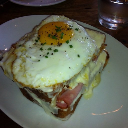

In [ ]:
for idx, (data_i_x, data_i_y) in enumerate(mkdataset.train_dataset):
  test_pred = test_model(data_i_x)
  print(test_pred)
  print(data_i_y)
  tmp_img = data_i_x[0].numpy()
  #test_label = tf.one_hot(data_i_y, 11)
  #test_loss = -tf.keras.losses.categorical_crossentropy(y_true=test_label, y_pred=test_pred)
  test_loss = tf.keras.losses.sparse_categorical_crossentropy(y_true=data_i_y, y_pred=test_pred)
  #test_acc = tf.keras.metrics.categorical_accuracy(y_true=test_label, y_pred=test_pred)
  test_acc = tf.keras.metrics.sparse_categorical_accuracy(y_true=data_i_y, y_pred=test_pred)
  print(test_loss)
  print(test_acc)
  break

cv2_imshow(tmp_img)

#5. Training

* find parameters

In [ ]:
train_batch_size = 64
mkdataset = MkTFDataset()
mkdataset.set_training_dataset(train_x, train_y, batch_size=train_batch_size)
mkdataset.set_validation_dataset(val_x, val_y)

learner = Learner(11, train_dataset=mkdataset.train_dataset, valid_dataset=mkdataset.valid_dataset)
learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)

learner.num_epochs = 100
learner.num_epochs_validation = 5
learner.train()

Epoch 5 12.34 sec(s) , Loss: 1.363537, CategoricalAccurancy:0.525846, Valid Loss: 1.730431, Valid CategoricalAccurancy:0.451020
Epoch 10 12.18 sec(s) , Loss: 1.082979, CategoricalAccurancy:0.618589, Valid Loss: 1.449796, Valid CategoricalAccurancy:0.534985
Epoch 15 12.17 sec(s) , Loss: 0.909380, CategoricalAccurancy:0.684472, Valid Loss: 1.429941, Valid CategoricalAccurancy:0.560641
Epoch 20 12.16 sec(s) , Loss: 0.755684, CategoricalAccurancy:0.738597, Valid Loss: 1.259898, Valid CategoricalAccurancy:0.603207
Epoch 25 12.16 sec(s) , Loss: 0.640624, CategoricalAccurancy:0.779039, Valid Loss: 1.275159, Valid CategoricalAccurancy:0.618367
Epoch 30 12.21 sec(s) , Loss: 0.528927, CategoricalAccurancy:0.818569, Valid Loss: 1.422525, Valid CategoricalAccurancy:0.593878
Epoch 35 12.13 sec(s) , Loss: 0.437395, CategoricalAccurancy:0.853031, Valid Loss: 1.502196, Valid CategoricalAccurancy:0.597376
Epoch 40 12.15 sec(s) , Loss: 0.355715, CategoricalAccurancy:0.877357, Valid Loss: 1.399303, Valid

* train dataset_train + dataset_valid

In [ ]:
train_val_x = np.concatenate((train_x, val_x), axis=0)
train_val_y = np.concatenate((train_y, val_y), axis=0)

In [ ]:
train_batch_size = 64
mkdataset = MkTFDataset()
mkdataset.set_training_dataset(train_val_x, train_val_y, batch_size=train_batch_size)
mkdataset.set_validation_dataset(val_x, val_y)

learner = Learner(11, train_dataset=mkdataset.train_dataset, valid_dataset=mkdataset.valid_dataset)
learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)

learner.num_epochs = 45
learner.num_epochs_validation = 5
learner.train()

Epoch 5 15.14 sec(s) , Loss: 1.305658, CategoricalAccurancy:0.549564, Valid Loss: 1.206711, Valid CategoricalAccurancy:0.578134
Epoch 10 14.98 sec(s) , Loss: 1.049994, CategoricalAccurancy:0.638688, Valid Loss: 0.943623, Valid CategoricalAccurancy:0.679592
Epoch 15 14.95 sec(s) , Loss: 0.874538, CategoricalAccurancy:0.697954, Valid Loss: 0.989623, Valid CategoricalAccurancy:0.661224
Epoch 20 14.86 sec(s) , Loss: 0.725115, CategoricalAccurancy:0.751579, Valid Loss: 0.777581, Valid CategoricalAccurancy:0.725947
Epoch 25 14.95 sec(s) , Loss: 0.616950, CategoricalAccurancy:0.785424, Valid Loss: 0.587056, Valid CategoricalAccurancy:0.797668
Epoch 30 14.93 sec(s) , Loss: 0.518785, CategoricalAccurancy:0.822277, Valid Loss: 0.448846, Valid CategoricalAccurancy:0.844315
Epoch 35 14.93 sec(s) , Loss: 0.443866, CategoricalAccurancy:0.848451, Valid Loss: 0.387989, Valid CategoricalAccurancy:0.869096
Epoch 40 14.92 sec(s) , Loss: 0.375279, CategoricalAccurancy:0.869660, Valid Loss: 0.567627, Valid

#### details: parameters with "Flip+Rotation" preprocessed data

In [ ]:
#train_batch_size = 256
#mkdataset.set_training_dataset(train2_x, train2_y, batch_size=train_batch_size)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 1 17.09 sec(s) , Loss: 3.733590, CategoricalAccurancy:0.248429, Valid Loss: 221.447174, Valid CategoricalAccurancy:0.094169
Epoch 2 11.93 sec(s) , Loss: 1.956072, CategoricalAccurancy:0.327387, Valid Loss: 25.273577, Valid CategoricalAccurancy:0.153644
Epoch 3 11.80 sec(s) , Loss: 1.800105, CategoricalAccurancy:0.373505, Valid Loss: 5.886127, Valid CategoricalAccurancy:0.271720
Epoch 4 11.80 sec(s) , Loss: 1.708212, CategoricalAccurancy:0.407561, Valid Loss: 10.776450, Valid CategoricalAccurancy:0.179883
Epoch 5 11.77 sec(s) , Loss: 1.608231, CategoricalAccurancy:0.441719, Valid Loss: 66.503014, Valid CategoricalAccurancy:0.123615
Epoch 6 11.88 sec(s) , Loss: 1.569154, CategoricalAccurancy:0.458747, Valid Loss: 6.854994, Valid CategoricalAccurancy:0.226822
Epoch 7 11.93 sec(s) , Loss: 1.503945, CategoricalAccurancy:0.470606, Valid Loss: 4.374528, Valid CategoricalAccurancy:0.264431
Epoch 8 11.79 sec(s) , Loss: 1.416537, CategoricalAccurancy:0.501824, Valid Loss: 4.149952, Valid CategoricalAccurancy:0.303207
Epoch 9 11.80 sec(s) , Loss: 1.332756, CategoricalAccurancy:0.528380, Valid Loss: 1.820665, Valid CategoricalAccurancy:0.414577
Epoch 10 11.78 sec(s) , Loss: 1.254179, CategoricalAccurancy:0.561524, Valid Loss: 1.870325, Valid CategoricalAccurancy:0.405539
"""

#### details: parameters with "RandomFlip" and "RandomRotation"

In [ ]:
#train_batch_size = 64
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07)
#learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
"""
Epoch 5 12.78 sec(s) , Loss: 1.624532, CategoricalAccurancy:0.430367, Valid Loss: 1.923249, Valid CategoricalAccurancy:0.366472
Epoch 10 12.65 sec(s) , Loss: 1.415513, CategoricalAccurancy:0.507298, Valid Loss: 2.400196, Valid CategoricalAccurancy:0.360058
Epoch 15 12.64 sec(s) , Loss: 1.216533, CategoricalAccurancy:0.573181, Valid Loss: 1.610323, Valid CategoricalAccurancy:0.490671
Epoch 20 12.64 sec(s) , Loss: 1.066913, CategoricalAccurancy:0.623454, Valid Loss: 1.709954, Valid CategoricalAccurancy:0.497085
Epoch 25 12.52 sec(s) , Loss: 0.920912, CategoricalAccurancy:0.678999, Valid Loss: 1.607727, Valid CategoricalAccurancy:0.511370
Epoch 30 12.65 sec(s) , Loss: 0.798612, CategoricalAccurancy:0.720961, Valid Loss: 1.553409, Valid CategoricalAccurancy:0.550437
Epoch 35 12.62 sec(s) , Loss: 0.630204, CategoricalAccurancy:0.777113, Valid Loss: 1.875095, Valid CategoricalAccurancy:0.542274
Epoch 40 12.55 sec(s) , Loss: 0.520693, CategoricalAccurancy:0.815325, Valid Loss: 1.812846, Valid CategoricalAccurancy:0.573761
Epoch 45 12.55 sec(s) , Loss: 0.422590, CategoricalAccurancy:0.851612, Valid Loss: 2.509364, Valid CategoricalAccurancy:0.519242
Epoch 50 12.66 sec(s) , Loss: 0.357593, CategoricalAccurancy:0.875735, Valid Loss: 2.288062, Valid CategoricalAccurancy:0.567055
Epoch 55 12.62 sec(s) , Loss: 0.298449, CategoricalAccurancy:0.895702, Valid Loss: 2.465500, Valid CategoricalAccurancy:0.564140
Epoch 60 12.57 sec(s) , Loss: 0.267032, CategoricalAccurancy:0.907561, Valid Loss: 2.648039, Valid CategoricalAccurancy:0.535860
Epoch 65 12.64 sec(s) , Loss: 0.201413, CategoricalAccurancy:0.930975, Valid Loss: 2.352108, Valid CategoricalAccurancy:0.597376
Epoch 70 12.61 sec(s) , Loss: 0.182080, CategoricalAccurancy:0.939895, Valid Loss: 2.561833, Valid CategoricalAccurancy:0.590379
Epoch 75 12.64 sec(s) , Loss: 0.189533, CategoricalAccurancy:0.935536, Valid Loss: 2.774184, Valid CategoricalAccurancy:0.584548
Epoch 80 12.62 sec(s) , Loss: 0.175667, CategoricalAccurancy:0.945368, Valid Loss: 3.405946, Valid CategoricalAccurancy:0.548105
Epoch 85 12.61 sec(s) , Loss: 0.147968, CategoricalAccurancy:0.951753, Valid Loss: 2.877167, Valid CategoricalAccurancy:0.590962
Epoch 90 12.57 sec(s) , Loss: 0.148113, CategoricalAccurancy:0.950334, Valid Loss: 3.191905, Valid CategoricalAccurancy:0.574052
Epoch 95 12.61 sec(s) , Loss: 0.123899, CategoricalAccurancy:0.962903, Valid Loss: 3.075211, Valid CategoricalAccurancy:0.593586
Epoch 100 12.69 sec(s) , Loss: 0.111177, CategoricalAccurancy:0.964829, Valid Loss: 3.328357, Valid CategoricalAccurancy:0.574052
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 10 13.83 sec(s) , Loss: 2.032444, CategoricalAccurancy:0.358605, Valid Loss: 2.348200, Valid CategoricalAccurancy:0.311953
Epoch 20 13.77 sec(s) , Loss: 1.632677, CategoricalAccurancy:0.448510, Valid Loss: 1.903213, Valid CategoricalAccurancy:0.395335
Epoch 30 13.71 sec(s) , Loss: 1.419448, CategoricalAccurancy:0.508210, Valid Loss: 1.796128, Valid CategoricalAccurancy:0.430321
Epoch 40 13.74 sec(s) , Loss: 1.267242, CategoricalAccurancy:0.563450, Valid Loss: 1.734295, Valid CategoricalAccurancy:0.466181
Epoch 50 13.80 sec(s) , Loss: 1.146849, CategoricalAccurancy:0.610480, Valid Loss: 1.665899, Valid CategoricalAccurancy:0.478134
Epoch 60 13.81 sec(s) , Loss: 1.052506, CategoricalAccurancy:0.639469, Valid Loss: 1.873854, Valid CategoricalAccurancy:0.451604
Epoch 70 13.82 sec(s) , Loss: 0.974945, CategoricalAccurancy:0.661869, Valid Loss: 1.839715, Valid CategoricalAccurancy:0.458601
Epoch 80 13.87 sec(s) , Loss: 0.886953, CategoricalAccurancy:0.694506, Valid Loss: 1.680274, Valid CategoricalAccurancy:0.511079
Epoch 90 13.77 sec(s) , Loss: 0.798997, CategoricalAccurancy:0.722887, Valid Loss: 1.765888, Valid CategoricalAccurancy:0.500000
Epoch 100 13.81 sec(s) , Loss: 0.732781, CategoricalAccurancy:0.748733, Valid Loss: 1.814528, Valid CategoricalAccurancy:0.500875
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 5 13.90 sec(s) , Loss: 1.625574, CategoricalAccurancy:0.432800, Valid Loss: 1.945962, Valid CategoricalAccurancy:0.368222
Epoch 10 13.93 sec(s) , Loss: 1.326148, CategoricalAccurancy:0.539428, Valid Loss: 2.005196, Valid CategoricalAccurancy:0.405831
Epoch 15 13.91 sec(s) , Loss: 1.132008, CategoricalAccurancy:0.608757, Valid Loss: 1.801661, Valid CategoricalAccurancy:0.467930
Epoch 20 13.93 sec(s) , Loss: 0.944323, CategoricalAccurancy:0.668255, Valid Loss: 1.842806, Valid CategoricalAccurancy:0.482799
Epoch 25 14.03 sec(s) , Loss: 0.805971, CategoricalAccurancy:0.716096, Valid Loss: 1.530352, Valid CategoricalAccurancy:0.558892
Epoch 30 13.88 sec(s) , Loss: 0.679280, CategoricalAccurancy:0.767484, Valid Loss: 1.616362, Valid CategoricalAccurancy:0.556268
Epoch 35 13.93 sec(s) , Loss: 0.575325, CategoricalAccurancy:0.804784, Valid Loss: 1.941809, Valid CategoricalAccurancy:0.533236
Epoch 40 13.92 sec(s) , Loss: 0.459806, CategoricalAccurancy:0.839651, Valid Loss: 1.967952, Valid CategoricalAccurancy:0.560933
"""

In [ ]:
#train_batch_size = 512
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
#learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
"""
Epoch 5 12.38 sec(s) , Loss: 1.813710, CategoricalAccurancy:0.376444, Valid Loss: 47.341763, Valid CategoricalAccurancy:0.178717
Epoch 10 12.24 sec(s) , Loss: 1.614370, CategoricalAccurancy:0.435638, Valid Loss: 20.967415, Valid CategoricalAccurancy:0.185423
Epoch 15 12.16 sec(s) , Loss: 1.474692, CategoricalAccurancy:0.484087, Valid Loss: 2.125658, Valid CategoricalAccurancy:0.366764
Epoch 20 12.24 sec(s) , Loss: 1.336547, CategoricalAccurancy:0.532840, Valid Loss: 2.118625, Valid CategoricalAccurancy:0.405539
Epoch 25 12.21 sec(s) , Loss: 1.197563, CategoricalAccurancy:0.577032, Valid Loss: 1.959018, Valid CategoricalAccurancy:0.395044
Epoch 30 12.43 sec(s) , Loss: 1.110792, CategoricalAccurancy:0.607338, Valid Loss: 1.622779, Valid CategoricalAccurancy:0.480175
Epoch 35 12.22 sec(s) , Loss: 0.996233, CategoricalAccurancy:0.653254, Valid Loss: 1.826498, Valid CategoricalAccurancy:0.486589
Epoch 40 12.26 sec(s) , Loss: 0.931141, CategoricalAccurancy:0.669674, Valid Loss: 1.632222, Valid CategoricalAccurancy:0.511079
Epoch 45 12.31 sec(s) , Loss: 0.840394, CategoricalAccurancy:0.705048, Valid Loss: 1.720048, Valid CategoricalAccurancy:0.514286
Epoch 50 12.26 sec(s) , Loss: 0.777744, CategoricalAccurancy:0.725421, Valid Loss: 1.863583, Valid CategoricalAccurancy:0.504373
Epoch 55 12.31 sec(s) , Loss: 0.697206, CategoricalAccurancy:0.748024, Valid Loss: 1.851485, Valid CategoricalAccurancy:0.526531
Epoch 60 12.22 sec(s) , Loss: 0.638654, CategoricalAccurancy:0.775187, Valid Loss: 2.053023, Valid CategoricalAccurancy:0.525073
Epoch 65 12.17 sec(s) , Loss: 0.586437, CategoricalAccurancy:0.792114, Valid Loss: 3.296294, Valid CategoricalAccurancy:0.446064
Epoch 70 12.15 sec(s) , Loss: 0.513582, CategoricalAccurancy:0.820697, Valid Loss: 2.375783, Valid CategoricalAccurancy:0.479300
Epoch 75 12.17 sec(s) , Loss: 0.512321, CategoricalAccurancy:0.821610, Valid Loss: 2.486082, Valid CategoricalAccurancy:0.503499
Epoch 80 12.18 sec(s) , Loss: 0.420556, CategoricalAccurancy:0.849584, Valid Loss: 2.429168, Valid CategoricalAccurancy:0.516035
Epoch 85 12.22 sec(s) , Loss: 0.378368, CategoricalAccurancy:0.864788, Valid Loss: 2.788758, Valid CategoricalAccurancy:0.518076
Epoch 90 12.19 sec(s) , Loss: 0.347364, CategoricalAccurancy:0.875431, Valid Loss: 3.144294, Valid CategoricalAccurancy:0.516618
Epoch 95 12.27 sec(s) , Loss: 0.340982, CategoricalAccurancy:0.879181, Valid Loss: 2.934750, Valid CategoricalAccurancy:0.521574
Epoch 100 12.17 sec(s) , Loss: 0.294863, CategoricalAccurancy:0.899047, Valid Loss: 2.711373, Valid CategoricalAccurancy:0.533819
"""

In [ ]:
#train_batch_size = 128
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
#learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
"""
Epoch 5 12.47 sec(s) , Loss: 1.762564, CategoricalAccurancy:0.383438, Valid Loss: 1.981148, Valid CategoricalAccurancy:0.298251
Epoch 10 12.16 sec(s) , Loss: 1.528463, CategoricalAccurancy:0.463308, Valid Loss: 1.844444, Valid CategoricalAccurancy:0.376385
Epoch 15 12.35 sec(s) , Loss: 1.401500, CategoricalAccurancy:0.510845, Valid Loss: 2.084523, Valid CategoricalAccurancy:0.398542
Epoch 20 12.25 sec(s) , Loss: 1.309093, CategoricalAccurancy:0.537503, Valid Loss: 2.184144, Valid CategoricalAccurancy:0.405831
Epoch 25 12.36 sec(s) , Loss: 1.221148, CategoricalAccurancy:0.572978, Valid Loss: 1.593172, Valid CategoricalAccurancy:0.490671
Epoch 30 12.24 sec(s) , Loss: 1.144024, CategoricalAccurancy:0.601054, Valid Loss: 1.758461, Valid CategoricalAccurancy:0.469096
Epoch 35 12.25 sec(s) , Loss: 1.066025, CategoricalAccurancy:0.625279, Valid Loss: 1.809106, Valid CategoricalAccurancy:0.480175
Epoch 40 12.46 sec(s) , Loss: 1.015609, CategoricalAccurancy:0.645753, Valid Loss: 1.670390, Valid CategoricalAccurancy:0.505539
Epoch 45 12.27 sec(s) , Loss: 0.971999, CategoricalAccurancy:0.659842, Valid Loss: 2.059369, Valid CategoricalAccurancy:0.472886
Epoch 50 12.28 sec(s) , Loss: 0.918318, CategoricalAccurancy:0.677174, Valid Loss: 1.305622, Valid CategoricalAccurancy:0.589796
Epoch 55 12.15 sec(s) , Loss: 0.886610, CategoricalAccurancy:0.688526, Valid Loss: 2.000343, Valid CategoricalAccurancy:0.497085
Epoch 60 12.29 sec(s) , Loss: 0.829604, CategoricalAccurancy:0.706467, Valid Loss: 1.713682, Valid CategoricalAccurancy:0.562391
Epoch 65 12.20 sec(s) , Loss: 0.790595, CategoricalAccurancy:0.724103, Valid Loss: 3.610368, Valid CategoricalAccurancy:0.414577
Epoch 70 12.14 sec(s) , Loss: 0.767172, CategoricalAccurancy:0.728867, Valid Loss: 1.694498, Valid CategoricalAccurancy:0.549563
Epoch 75 12.15 sec(s) , Loss: 0.743764, CategoricalAccurancy:0.744577, Valid Loss: 1.734061, Valid CategoricalAccurancy:0.562974
Epoch 80 12.19 sec(s) , Loss: 0.686016, CategoricalAccurancy:0.760389, Valid Loss: 2.132046, Valid CategoricalAccurancy:0.554519
Epoch 85 12.27 sec(s) , Loss: 0.646848, CategoricalAccurancy:0.771539, Valid Loss: 3.318575, Valid CategoricalAccurancy:0.425656
Epoch 90 12.28 sec(s) , Loss: 0.617684, CategoricalAccurancy:0.783600, Valid Loss: 2.048015, Valid CategoricalAccurancy:0.542857
Epoch 95 12.22 sec(s) , Loss: 0.584710, CategoricalAccurancy:0.797892, Valid Loss: 1.712108, Valid CategoricalAccurancy:0.591545
Epoch 100 12.25 sec(s) , Loss: 0.558974, CategoricalAccurancy:0.805595, Valid Loss: 1.751824, Valid CategoricalAccurancy:0.605539
"""

In [ ]:
#train_batch_size = 64
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
#learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
"""
Epoch 10 12.81 sec(s) , Loss: 1.775738, CategoricalAccurancy:0.366613, Valid Loss: 2.024456, Valid CategoricalAccurancy:0.333528
Epoch 20 12.50 sec(s) , Loss: 1.500741, CategoricalAccurancy:0.471822, Valid Loss: 1.963377, Valid CategoricalAccurancy:0.384257
Epoch 30 12.54 sec(s) , Loss: 1.356945, CategoricalAccurancy:0.523515, Valid Loss: 1.559655, Valid CategoricalAccurancy:0.473178
Epoch 40 12.49 sec(s) , Loss: 1.239090, CategoricalAccurancy:0.567403, Valid Loss: 1.973971, Valid CategoricalAccurancy:0.424490
Epoch 50 12.56 sec(s) , Loss: 1.123880, CategoricalAccurancy:0.612102, Valid Loss: 2.427073, Valid CategoricalAccurancy:0.338484
Epoch 60 12.50 sec(s) , Loss: 1.048376, CategoricalAccurancy:0.635212, Valid Loss: 1.768765, Valid CategoricalAccurancy:0.505831
Epoch 70 12.47 sec(s) , Loss: 0.958305, CategoricalAccurancy:0.669572, Valid Loss: 1.419110, Valid CategoricalAccurancy:0.557726
Epoch 80 12.60 sec(s) , Loss: 0.888924, CategoricalAccurancy:0.696534, Valid Loss: 2.034102, Valid CategoricalAccurancy:0.502041
Epoch 90 12.46 sec(s) , Loss: 0.831681, CategoricalAccurancy:0.718832, Valid Loss: 1.364187, Valid CategoricalAccurancy:0.581633
Epoch 100 12.45 sec(s) , Loss: 0.714613, CategoricalAccurancy:0.750051, Valid Loss: 1.432665, Valid CategoricalAccurancy:0.602041
"""

In [ ]:
#train_batch_size = 32
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
#learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
"""
Epoch 10 13.34 sec(s) , Loss: 1.598364, CategoricalAccurancy:0.438982, Valid Loss: 2.034113, Valid CategoricalAccurancy:0.373178
Epoch 20 13.27 sec(s) , Loss: 1.409368, CategoricalAccurancy:0.511352, Valid Loss: 2.318501, Valid CategoricalAccurancy:0.368513
Epoch 30 13.28 sec(s) , Loss: 1.261190, CategoricalAccurancy:0.566998, Valid Loss: 1.801500, Valid CategoricalAccurancy:0.450146
Epoch 40 13.31 sec(s) , Loss: 1.143714, CategoricalAccurancy:0.615954, Valid Loss: 2.248391, Valid CategoricalAccurancy:0.424490
Epoch 50 13.26 sec(s) , Loss: 1.037775, CategoricalAccurancy:0.647882, Valid Loss: 1.527069, Valid CategoricalAccurancy:0.557726
Epoch 60 13.47 sec(s) , Loss: 0.952101, CategoricalAccurancy:0.682546, Valid Loss: 1.449517, Valid CategoricalAccurancy:0.585714
Epoch 70 13.18 sec(s) , Loss: 0.888536, CategoricalAccurancy:0.706061, Valid Loss: 1.725811, Valid CategoricalAccurancy:0.565889
Epoch 80 13.11 sec(s) , Loss: 0.831699, CategoricalAccurancy:0.722785, Valid Loss: 2.001540, Valid CategoricalAccurancy:0.539359
Epoch 90 13.15 sec(s) , Loss: 0.733055, CategoricalAccurancy:0.752787, Valid Loss: 1.800089, Valid CategoricalAccurancy:0.573178
Epoch 100 13.20 sec(s) , Loss: 0.668461, CategoricalAccurancy:0.782384, Valid Loss: 8.628928, Valid CategoricalAccurancy:0.248980
"""

In [ ]:
#train_batch_size = 16
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
#learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
"""
Epoch 10 14.76 sec(s) , Loss: 1.875797, CategoricalAccurancy:0.340361, Valid Loss: 2.211635, Valid CategoricalAccurancy:0.289213
Epoch 20 14.46 sec(s) , Loss: 1.672827, CategoricalAccurancy:0.403507, Valid Loss: 1.756392, Valid CategoricalAccurancy:0.404665
Epoch 30 14.32 sec(s) , Loss: 1.500101, CategoricalAccurancy:0.469288, Valid Loss: 1.662252, Valid CategoricalAccurancy:0.438192
Epoch 40 14.37 sec(s) , Loss: 1.382779, CategoricalAccurancy:0.515711, Valid Loss: 1.982856, Valid CategoricalAccurancy:0.351020
Epoch 50 14.33 sec(s) , Loss: 1.292041, CategoricalAccurancy:0.553720, Valid Loss: 1.525022, Valid CategoricalAccurancy:0.494752
Epoch 60 14.43 sec(s) , Loss: 1.213068, CategoricalAccurancy:0.582303, Valid Loss: 1.476868, Valid CategoricalAccurancy:0.522449
Epoch 70 14.33 sec(s) , Loss: 1.127429, CategoricalAccurancy:0.608555, Valid Loss: 1.661510, Valid CategoricalAccurancy:0.513994
Epoch 80 14.32 sec(s) , Loss: 1.092911, CategoricalAccurancy:0.630955, Valid Loss: 1.695721, Valid CategoricalAccurancy:0.521866
Epoch 90 14.32 sec(s) , Loss: 1.032423, CategoricalAccurancy:0.646665, Valid Loss: 1.646097, Valid CategoricalAccurancy:0.521574
Epoch 100 14.34 sec(s) , Loss: 0.987482, CategoricalAccurancy:0.673627, Valid Loss: 1.992897, Valid CategoricalAccurancy:0.486297
"""

In [ ]:
#train_batch_size = 64
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
#learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
"""
Epoch 5 12.34 sec(s) , Loss: 1.363537, CategoricalAccurancy:0.525846, Valid Loss: 1.730431, Valid CategoricalAccurancy:0.451020
Epoch 10 12.18 sec(s) , Loss: 1.082979, CategoricalAccurancy:0.618589, Valid Loss: 1.449796, Valid CategoricalAccurancy:0.534985
Epoch 15 12.17 sec(s) , Loss: 0.909380, CategoricalAccurancy:0.684472, Valid Loss: 1.429941, Valid CategoricalAccurancy:0.560641
Epoch 20 12.16 sec(s) , Loss: 0.755684, CategoricalAccurancy:0.738597, Valid Loss: 1.259898, Valid CategoricalAccurancy:0.603207
Epoch 25 12.16 sec(s) , Loss: 0.640624, CategoricalAccurancy:0.779039, Valid Loss: 1.275159, Valid CategoricalAccurancy:0.618367
Epoch 30 12.21 sec(s) , Loss: 0.528927, CategoricalAccurancy:0.818569, Valid Loss: 1.422525, Valid CategoricalAccurancy:0.593878
Epoch 35 12.13 sec(s) , Loss: 0.437395, CategoricalAccurancy:0.853031, Valid Loss: 1.502196, Valid CategoricalAccurancy:0.597376
*Epoch 40 12.15 sec(s) , Loss: 0.355715, CategoricalAccurancy:0.877357, Valid Loss: 1.399303, Valid CategoricalAccurancy:0.638192 
Epoch 45 12.20 sec(s) , Loss: 0.312326, CategoricalAccurancy:0.893168, Valid Loss: 1.399999, Valid CategoricalAccurancy:0.643732
Epoch 50 12.22 sec(s) , Loss: 0.242799, CategoricalAccurancy:0.917190, Valid Loss: 1.768504, Valid CategoricalAccurancy:0.590962
Epoch 55 12.15 sec(s) , Loss: 0.204825, CategoricalAccurancy:0.930874, Valid Loss: 2.240878, Valid CategoricalAccurancy:0.591837
Epoch 60 12.18 sec(s) , Loss: 0.181745, CategoricalAccurancy:0.937259, Valid Loss: 1.956529, Valid CategoricalAccurancy:0.617493
Epoch 65 12.13 sec(s) , Loss: 0.163329, CategoricalAccurancy:0.946077, Valid Loss: 1.945341, Valid CategoricalAccurancy:0.616618
Epoch 70 12.11 sec(s) , Loss: 0.147186, CategoricalAccurancy:0.949220, Valid Loss: 2.459524, Valid CategoricalAccurancy:0.612828
Epoch 75 12.13 sec(s) , Loss: 0.133216, CategoricalAccurancy:0.955200, Valid Loss: 2.573884, Valid CategoricalAccurancy:0.596793
Epoch 80 12.14 sec(s) , Loss: 0.125941, CategoricalAccurancy:0.957632, Valid Loss: 2.013787, Valid CategoricalAccurancy:0.644898
Epoch 85 12.14 sec(s) , Loss: 0.108098, CategoricalAccurancy:0.961078, Valid Loss: 2.364472, Valid CategoricalAccurancy:0.623032
Epoch 90 12.13 sec(s) , Loss: 0.102450, CategoricalAccurancy:0.964423, Valid Loss: 2.257217, Valid CategoricalAccurancy:0.648396
Epoch 95 12.18 sec(s) , Loss: 0.100331, CategoricalAccurancy:0.968174, Valid Loss: 2.506389, Valid CategoricalAccurancy:0.638192
Epoch 100 12.10 sec(s) , Loss: 0.093230, CategoricalAccurancy:0.970606, Valid Loss: 2.697342, Valid CategoricalAccurancy:0.624198
"""

In [ ]:
#train_batch_size = 64
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
#learner.model = CNNModel_Rotation(pic_height=128, pic_width=128, n_classes=11)
"""
Epoch 5 12.33 sec(s) , Loss: 1.387993, CategoricalAccurancy:0.518853, Valid Loss: 1.724764, Valid CategoricalAccurancy:0.439067
Epoch 10 12.07 sec(s) , Loss: 1.126148, CategoricalAccurancy:0.609974, Valid Loss: 1.377208, Valid CategoricalAccurancy:0.540816
Epoch 15 12.10 sec(s) , Loss: 0.957896, CategoricalAccurancy:0.669065, Valid Loss: 1.238297, Valid CategoricalAccurancy:0.594752
Epoch 20 12.15 sec(s) , Loss: 0.833561, CategoricalAccurancy:0.712548, Valid Loss: 1.352397, Valid CategoricalAccurancy:0.581341
Epoch 25 12.13 sec(s) , Loss: 0.707253, CategoricalAccurancy:0.760288, Valid Loss: 1.257358, Valid CategoricalAccurancy:0.597959
Epoch 30 12.12 sec(s) , Loss: 0.601838, CategoricalAccurancy:0.794141, Valid Loss: 1.446457, Valid CategoricalAccurancy:0.576385
Epoch 35 12.10 sec(s) , Loss: 0.517178, CategoricalAccurancy:0.821306, Valid Loss: 1.340881, Valid CategoricalAccurancy:0.610787
Epoch 40 12.29 sec(s) , Loss: 0.432130, CategoricalAccurancy:0.854652, Valid Loss: 1.443518, Valid CategoricalAccurancy:0.609329
Epoch 45 12.11 sec(s) , Loss: 0.362684, CategoricalAccurancy:0.879586, Valid Loss: 1.333880, Valid CategoricalAccurancy:0.616910
Epoch 50 12.25 sec(s) , Loss: 0.304709, CategoricalAccurancy:0.899959, Valid Loss: 1.606322, Valid CategoricalAccurancy:0.593586
Epoch 55 12.14 sec(s) , Loss: 0.257801, CategoricalAccurancy:0.915974, Valid Loss: 1.458625, Valid CategoricalAccurancy:0.638192
Epoch 60 12.18 sec(s) , Loss: 0.211347, CategoricalAccurancy:0.933104, Valid Loss: 1.515131, Valid CategoricalAccurancy:0.636735
Epoch 65 12.12 sec(s) , Loss: 0.188437, CategoricalAccurancy:0.940503, Valid Loss: 1.607294, Valid CategoricalAccurancy:0.634694
Epoch 70 12.15 sec(s) , Loss: 0.158081, CategoricalAccurancy:0.951145, Valid Loss: 1.732198, Valid CategoricalAccurancy:0.627697
Epoch 75 12.25 sec(s) , Loss: 0.143010, CategoricalAccurancy:0.956416, Valid Loss: 1.603605, Valid CategoricalAccurancy:0.648396
Epoch 80 12.18 sec(s) , Loss: 0.117518, CategoricalAccurancy:0.962700, Valid Loss: 2.004308, Valid CategoricalAccurancy:0.616910
Epoch 85 12.17 sec(s) , Loss: 0.106781, CategoricalAccurancy:0.965538, Valid Loss: 1.924662, Valid CategoricalAccurancy:0.620700
Epoch 90 12.15 sec(s) , Loss: 0.100547, CategoricalAccurancy:0.966349, Valid Loss: 2.017897, Valid CategoricalAccurancy:0.614869
Epoch 95 12.17 sec(s) , Loss: 0.090108, CategoricalAccurancy:0.970707, Valid Loss: 1.885097, Valid CategoricalAccurancy:0.637901
Epoch 100 12.16 sec(s) , Loss: 0.084144, CategoricalAccurancy:0.972126, Valid Loss: 2.024556, Valid CategoricalAccurancy:0.637026
"""

#### details: parameters w/o "RandomFlip" and "RandomRotation"

In [ ]:
#train_batch_size = 8
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.1, beta_1=0.99, beta_2=0.99, epsilon=1e-09)
"""
Epoch 1 20.70 sec(s) , Loss: 3676518043615232.000000, CategoricalAccurancy:0.143726, Valid Loss: 2.319529, Valid CategoricalAccurancy:0.130904
Epoch 2 19.54 sec(s) , Loss: 2.317328, CategoricalAccurancy:0.143726, Valid Loss: 2.318568, Valid CategoricalAccurancy:0.145773
Epoch 3 19.56 sec(s) , Loss: 2.313444, CategoricalAccurancy:0.144334, Valid Loss: 2.329194, Valid CategoricalAccurancy:0.145773
Epoch 4 19.44 sec(s) , Loss: 2.323724, CategoricalAccurancy:0.139976, Valid Loss: 2.322262, Valid CategoricalAccurancy:0.145773
Epoch 5 19.45 sec(s) , Loss: 2.316225, CategoricalAccurancy:0.143321, Valid Loss: 2.308837, Valid CategoricalAccurancy:0.145773
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.99, beta_2=0.99, epsilon=1e-09)
"""
Epoch 1 14.53 sec(s) , Loss: 716.405518, CategoricalAccurancy:0.109163, Valid Loss: 152.421173, Valid CategoricalAccurancy:0.182507
Epoch 2 13.34 sec(s) , Loss: 77.325424, CategoricalAccurancy:0.129941, Valid Loss: 42.586040, Valid CategoricalAccurancy:0.153061
Epoch 3 13.30 sec(s) , Loss: 35.587051, CategoricalAccurancy:0.168761, Valid Loss: 22.835489, Valid CategoricalAccurancy:0.184548
Epoch 4 13.32 sec(s) , Loss: 25.746601, CategoricalAccurancy:0.194101, Valid Loss: 21.424284, Valid CategoricalAccurancy:0.194752
Epoch 5 13.38 sec(s) , Loss: 21.603741, CategoricalAccurancy:0.162680, Valid Loss: 18.649895, Valid CategoricalAccurancy:0.122449
"""

In [ ]:
#train_batch_size = 128
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.99, beta_2=0.99, epsilon=1e-09)
"""
Epoch 1 14.47 sec(s) , Loss: 252.862839, CategoricalAccurancy:0.115548, Valid Loss: 54.982162, Valid CategoricalAccurancy:0.116910
Epoch 2 13.49 sec(s) , Loss: 54.545540, CategoricalAccurancy:0.151936, Valid Loss: 67.837456, Valid CategoricalAccurancy:0.148688
Epoch 3 13.43 sec(s) , Loss: 47.335560, CategoricalAccurancy:0.155585, Valid Loss: 51.644218, Valid CategoricalAccurancy:0.143149
Epoch 4 13.38 sec(s) , Loss: 36.076782, CategoricalAccurancy:0.151632, Valid Loss: 153.856400, Valid CategoricalAccurancy:0.133819
Epoch 5 13.41 sec(s) , Loss: 117.259132, CategoricalAccurancy:0.138151, Valid Loss: 304.223694, Valid CategoricalAccurancy:0.107872
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.99, beta_2=0.99, epsilon=1e-09)
"""
Epoch 1 14.17 sec(s) , Loss: 21.156895, CategoricalAccurancy:0.154875, Valid Loss: 5.281346, Valid CategoricalAccurancy:0.177551
Epoch 2 13.39 sec(s) , Loss: 3.937636, CategoricalAccurancy:0.230894, Valid Loss: 3.056758, Valid CategoricalAccurancy:0.240525
Epoch 3 13.39 sec(s) , Loss: 2.719815, CategoricalAccurancy:0.246503, Valid Loss: 2.466967, Valid CategoricalAccurancy:0.266764
Epoch 4 13.31 sec(s) , Loss: 2.223764, CategoricalAccurancy:0.299919, Valid Loss: 2.163775, Valid CategoricalAccurancy:0.281050
Epoch 5 13.32 sec(s) , Loss: 1.969413, CategoricalAccurancy:0.329516, Valid Loss: 2.002997, Valid CategoricalAccurancy:0.293878
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.99, beta_2=0.99, epsilon=1e-09)
"""
Epoch 1 14.20 sec(s) , Loss: 10.278316, CategoricalAccurancy:0.172005, Valid Loss: 7.202267, Valid CategoricalAccurancy:0.193586
Epoch 2 13.58 sec(s) , Loss: 5.262107, CategoricalAccurancy:0.218934, Valid Loss: 4.051261, Valid CategoricalAccurancy:0.241691
Epoch 3 13.39 sec(s) , Loss: 3.836896, CategoricalAccurancy:0.276911, Valid Loss: 3.160650, Valid CategoricalAccurancy:0.272595
Epoch 4 13.28 sec(s) , Loss: 3.001806, CategoricalAccurancy:0.285931, Valid Loss: 3.168032, Valid CategoricalAccurancy:0.291254
Epoch 5 13.26 sec(s) , Loss: 2.559707, CategoricalAccurancy:0.317150, Valid Loss: 2.549547, Valid CategoricalAccurancy:0.295918
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.75, beta_2=0.9, epsilon=1e-09)
"""
Epoch 1 14.11 sec(s) , Loss: 8.219105, CategoricalAccurancy:0.166025, Valid Loss: 4.897593, Valid CategoricalAccurancy:0.209038
Epoch 2 13.36 sec(s) , Loss: 4.210209, CategoricalAccurancy:0.233225, Valid Loss: 3.860836, Valid CategoricalAccurancy:0.213703
Epoch 3 13.37 sec(s) , Loss: 3.377116, CategoricalAccurancy:0.272451, Valid Loss: 3.559670, Valid CategoricalAccurancy:0.249854
Epoch 4 13.27 sec(s) , Loss: 2.843278, CategoricalAccurancy:0.302453, Valid Loss: 3.049640, Valid CategoricalAccurancy:0.273761
Epoch 5 13.35 sec(s) , Loss: 2.467074, CategoricalAccurancy:0.347050, Valid Loss: 2.967757, Valid CategoricalAccurancy:0.297376
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.5, beta_2=0.9, epsilon=1e-09)
"""
Epoch 1 14.32 sec(s) , Loss: 9.364065, CategoricalAccurancy:0.158524, Valid Loss: 5.900089, Valid CategoricalAccurancy:0.191254
Epoch 2 13.34 sec(s) , Loss: 5.294988, CategoricalAccurancy:0.223698, Valid Loss: 4.536930, Valid CategoricalAccurancy:0.214869
Epoch 3 13.34 sec(s) , Loss: 4.047153, CategoricalAccurancy:0.257957, Valid Loss: 4.357635, Valid CategoricalAccurancy:0.264431
Epoch 4 13.30 sec(s) , Loss: 3.285313, CategoricalAccurancy:0.294243, Valid Loss: 3.106086, Valid CategoricalAccurancy:0.271429
Epoch 5 13.34 sec(s) , Loss: 2.816802, CategoricalAccurancy:0.324042, Valid Loss: 2.904456, Valid CategoricalAccurancy:0.294461
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.75, beta_2=0.8, epsilon=1e-09)
"""
Epoch 1 14.15 sec(s) , Loss: 9.423850, CategoricalAccurancy:0.162477, Valid Loss: 4.979230, Valid CategoricalAccurancy:0.190379
Epoch 2 13.28 sec(s) , Loss: 3.849723, CategoricalAccurancy:0.251976, Valid Loss: 3.713085, Valid CategoricalAccurancy:0.256851
Epoch 3 13.30 sec(s) , Loss: 3.011535, CategoricalAccurancy:0.299311, Valid Loss: 3.250370, Valid CategoricalAccurancy:0.271720
Epoch 4 13.29 sec(s) , Loss: 2.597751, CategoricalAccurancy:0.333874, Valid Loss: 2.801024, Valid CategoricalAccurancy:0.279009
Epoch 5 13.26 sec(s) , Loss: 2.205405, CategoricalAccurancy:0.376850, Valid Loss: 2.820027, Valid CategoricalAccurancy:0.315743
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.75, beta_2=0.7, epsilon=1e-09)
"""
Epoch 1 14.22 sec(s) , Loss: 8.294810, CategoricalAccurancy:0.176667, Valid Loss: 4.607496, Valid CategoricalAccurancy:0.212245
Epoch 2 13.35 sec(s) , Loss: 3.701077, CategoricalAccurancy:0.260186, Valid Loss: 3.459048, Valid CategoricalAccurancy:0.243732
Epoch 3 13.41 sec(s) , Loss: 2.873345, CategoricalAccurancy:0.307318, Valid Loss: 3.446273, Valid CategoricalAccurancy:0.257726
Epoch 4 13.33 sec(s) , Loss: 2.441847, CategoricalAccurancy:0.345327, Valid Loss: 2.921659, Valid CategoricalAccurancy:0.288338
Epoch 5 13.42 sec(s) , Loss: 2.089480, CategoricalAccurancy:0.390229, Valid Loss: 2.932273, Valid CategoricalAccurancy:0.292711
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 1 14.14 sec(s) , Loss: 9.927155, CategoricalAccurancy:0.182546, Valid Loss: 4.472664, Valid CategoricalAccurancy:0.204956
Epoch 2 13.32 sec(s) , Loss: 3.615950, CategoricalAccurancy:0.269816, Valid Loss: 3.550405, Valid CategoricalAccurancy:0.257434
Epoch 3 13.38 sec(s) , Loss: 2.744015, CategoricalAccurancy:0.323231, Valid Loss: 2.828467, Valid CategoricalAccurancy:0.282216
Epoch 4 13.31 sec(s) , Loss: 2.309552, CategoricalAccurancy:0.362660, Valid Loss: 2.846933, Valid CategoricalAccurancy:0.301749
Epoch 5 13.40 sec(s) , Loss: 1.992928, CategoricalAccurancy:0.408271, Valid Loss: 2.595855, Valid CategoricalAccurancy:0.303790
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.75, beta_2=0.3, epsilon=1e-09)
"""
Epoch 1 14.16 sec(s) , Loss: 8.852455, CategoricalAccurancy:0.169775, Valid Loss: 5.326957, Valid CategoricalAccurancy:0.186589
Epoch 2 13.36 sec(s) , Loss: 3.665827, CategoricalAccurancy:0.245895, Valid Loss: 3.816739, Valid CategoricalAccurancy:0.243440
Epoch 3 13.32 sec(s) , Loss: 3.923931, CategoricalAccurancy:0.290797, Valid Loss: 3.477874, Valid CategoricalAccurancy:0.255394
Epoch 4 13.32 sec(s) , Loss: 6.313934, CategoricalAccurancy:0.291608, Valid Loss: 8.160707, Valid CategoricalAccurancy:0.152478
Epoch 5 13.31 sec(s) , Loss: 7.228810, CategoricalAccurancy:0.198662, Valid Loss: 4.592516, Valid CategoricalAccurancy:0.209913
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 1 14.15 sec(s) , Loss: 7.555224, CategoricalAccurancy:0.181634, Valid Loss: 4.260848, Valid CategoricalAccurancy:0.201749
Epoch 2 13.30 sec(s) , Loss: 3.430051, CategoricalAccurancy:0.263329, Valid Loss: 3.082241, Valid CategoricalAccurancy:0.270554
Epoch 3 13.28 sec(s) , Loss: 2.672838, CategoricalAccurancy:0.317758, Valid Loss: 2.730170, Valid CategoricalAccurancy:0.288630
Epoch 4 13.30 sec(s) , Loss: 2.336097, CategoricalAccurancy:0.353943, Valid Loss: 2.826650, Valid CategoricalAccurancy:0.293586
Epoch 5 13.31 sec(s) , Loss: 2.018887, CategoricalAccurancy:0.400264, Valid Loss: 2.629900, Valid CategoricalAccurancy:0.323324
Epoch 6 13.35 sec(s) , Loss: 1.805696, CategoricalAccurancy:0.439084, Valid Loss: 2.395027, Valid CategoricalAccurancy:0.340525
Epoch 7 13.28 sec(s) , Loss: 1.588435, CategoricalAccurancy:0.486621, Valid Loss: 2.322941, Valid CategoricalAccurancy:0.344023
Epoch 8 13.24 sec(s) , Loss: 1.439349, CategoricalAccurancy:0.525745, Valid Loss: 2.228357, Valid CategoricalAccurancy:0.361808
Epoch 9 13.27 sec(s) , Loss: 1.308466, CategoricalAccurancy:0.566694, Valid Loss: 2.265125, Valid CategoricalAccurancy:0.352478
Epoch 10 13.26 sec(s) , Loss: 1.186241, CategoricalAccurancy:0.601054, Valid Loss: 2.205420, Valid CategoricalAccurancy:0.378426
Epoch 11 13.31 sec(s) , Loss: 1.109285, CategoricalAccurancy:0.624468, Valid Loss: 2.238398, Valid CategoricalAccurancy:0.367055
Epoch 12 13.27 sec(s) , Loss: 0.980652, CategoricalAccurancy:0.666937, Valid Loss: 2.176457, Valid CategoricalAccurancy:0.379009
Epoch 13 13.26 sec(s) , Loss: 0.895151, CategoricalAccurancy:0.700487, Valid Loss: 2.172870, Valid CategoricalAccurancy:0.379009
Epoch 14 13.58 sec(s) , Loss: 0.803866, CategoricalAccurancy:0.734948, Valid Loss: 2.150154, Valid CategoricalAccurancy:0.395044
Epoch 15 13.31 sec(s) , Loss: 0.715595, CategoricalAccurancy:0.769511, Valid Loss: 2.142486, Valid CategoricalAccurancy:0.403207
Epoch 16 13.29 sec(s) , Loss: 0.646344, CategoricalAccurancy:0.798297, Valid Loss: 2.186787, Valid CategoricalAccurancy:0.408455
Epoch 17 13.26 sec(s) , Loss: 0.586238, CategoricalAccurancy:0.819380, Valid Loss: 2.170016, Valid CategoricalAccurancy:0.401166
Epoch 18 13.32 sec(s) , Loss: 0.523993, CategoricalAccurancy:0.848165, Valid Loss: 2.173876, Valid CategoricalAccurancy:0.395627
Epoch 19 13.30 sec(s) , Loss: 0.490835, CategoricalAccurancy:0.861443, Valid Loss: 2.211869, Valid CategoricalAccurancy:0.405539
Epoch 20 13.32 sec(s) , Loss: 0.412301, CategoricalAccurancy:0.892966, Valid Loss: 2.145678, Valid CategoricalAccurancy:0.416327
Epoch 21 13.29 sec(s) , Loss: 0.382622, CategoricalAccurancy:0.901480, Valid Loss: 2.219144, Valid CategoricalAccurancy:0.424490
Epoch 22 13.29 sec(s) , Loss: 0.344451, CategoricalAccurancy:0.915873, Valid Loss: 2.147987, Valid CategoricalAccurancy:0.420117
Epoch 23 13.28 sec(s) , Loss: 0.295567, CategoricalAccurancy:0.936651, Valid Loss: 2.344147, Valid CategoricalAccurancy:0.412828
Epoch 24 13.33 sec(s) , Loss: 0.261615, CategoricalAccurancy:0.948105, Valid Loss: 2.226998, Valid CategoricalAccurancy:0.427405
Epoch 25 13.32 sec(s) , Loss: 0.238417, CategoricalAccurancy:0.952058, Valid Loss: 2.253212, Valid CategoricalAccurancy:0.430904
Epoch 26 13.29 sec(s) , Loss: 0.212061, CategoricalAccurancy:0.963004, Valid Loss: 2.318209, Valid CategoricalAccurancy:0.425656
Epoch 27 13.32 sec(s) , Loss: 0.187896, CategoricalAccurancy:0.970302, Valid Loss: 2.317805, Valid CategoricalAccurancy:0.414869
Epoch 28 13.32 sec(s) , Loss: 0.161462, CategoricalAccurancy:0.978613, Valid Loss: 2.327672, Valid CategoricalAccurancy:0.428571
Epoch 29 13.35 sec(s) , Loss: 0.143849, CategoricalAccurancy:0.981553, Valid Loss: 2.376177, Valid CategoricalAccurancy:0.436443
Epoch 30 13.34 sec(s) , Loss: 0.128354, CategoricalAccurancy:0.984087, Valid Loss: 2.345926, Valid CategoricalAccurancy:0.449271
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.000001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 1 14.16 sec(s) , Loss: 11.945652, CategoricalAccurancy:0.111798, Valid Loss: 7.105508, Valid CategoricalAccurancy:0.135569
Epoch 2 13.30 sec(s) , Loss: 6.084249, CategoricalAccurancy:0.162376, Valid Loss: 5.525168, Valid CategoricalAccurancy:0.171720
Epoch 3 13.38 sec(s) , Loss: 5.075434, CategoricalAccurancy:0.197750, Valid Loss: 4.915099, Valid CategoricalAccurancy:0.186880
Epoch 4 13.44 sec(s) , Loss: 4.587085, CategoricalAccurancy:0.218021, Valid Loss: 4.656775, Valid CategoricalAccurancy:0.198834
Epoch 5 13.39 sec(s) , Loss: 4.257432, CategoricalAccurancy:0.232820, Valid Loss: 4.432166, Valid CategoricalAccurancy:0.211370
Epoch 6 13.35 sec(s) , Loss: 3.987693, CategoricalAccurancy:0.245996, Valid Loss: 4.239059, Valid CategoricalAccurancy:0.223615
Epoch 7 13.31 sec(s) , Loss: 3.773976, CategoricalAccurancy:0.252686, Valid Loss: 4.069938, Valid CategoricalAccurancy:0.225364
Epoch 8 13.33 sec(s) , Loss: 3.591254, CategoricalAccurancy:0.263025, Valid Loss: 4.011240, Valid CategoricalAccurancy:0.237026
Epoch 9 13.31 sec(s) , Loss: 3.440452, CategoricalAccurancy:0.271133, Valid Loss: 3.944484, Valid CategoricalAccurancy:0.231778
Epoch 10 13.35 sec(s) , Loss: 3.302073, CategoricalAccurancy:0.282283, Valid Loss: 3.745410, Valid CategoricalAccurancy:0.239359
Epoch 11 13.33 sec(s) , Loss: 3.171273, CategoricalAccurancy:0.288871, Valid Loss: 3.731919, Valid CategoricalAccurancy:0.235860
Epoch 12 13.30 sec(s) , Loss: 3.075191, CategoricalAccurancy:0.297588, Valid Loss: 3.608407, Valid CategoricalAccurancy:0.234985
Epoch 13 13.33 sec(s) , Loss: 2.959112, CategoricalAccurancy:0.305088, Valid Loss: 3.525803, Valid CategoricalAccurancy:0.241691
Epoch 14 13.37 sec(s) , Loss: 2.863588, CategoricalAccurancy:0.315427, Valid Loss: 3.486575, Valid CategoricalAccurancy:0.247522
Epoch 15 13.34 sec(s) , Loss: 2.787152, CategoricalAccurancy:0.322522, Valid Loss: 3.421645, Valid CategoricalAccurancy:0.248980
Epoch 16 13.36 sec(s) , Loss: 2.700678, CategoricalAccurancy:0.331847, Valid Loss: 3.381177, Valid CategoricalAccurancy:0.263557
Epoch 17 13.32 sec(s) , Loss: 2.629031, CategoricalAccurancy:0.337624, Valid Loss: 3.321454, Valid CategoricalAccurancy:0.249563
Epoch 18 13.29 sec(s) , Loss: 2.566008, CategoricalAccurancy:0.345226, Valid Loss: 3.337970, Valid CategoricalAccurancy:0.262682
Epoch 19 13.28 sec(s) , Loss: 2.502299, CategoricalAccurancy:0.354044, Valid Loss: 3.280564, Valid CategoricalAccurancy:0.260641
Epoch 20 13.32 sec(s) , Loss: 2.435586, CategoricalAccurancy:0.364383, Valid Loss: 3.252551, Valid CategoricalAccurancy:0.253936
Epoch 21 13.33 sec(s) , Loss: 2.388642, CategoricalAccurancy:0.365599, Valid Loss: 3.207732, Valid CategoricalAccurancy:0.264431
Epoch 22 13.31 sec(s) , Loss: 2.331559, CategoricalAccurancy:0.378370, Valid Loss: 3.208599, Valid CategoricalAccurancy:0.270554
Epoch 23 13.32 sec(s) , Loss: 2.279535, CategoricalAccurancy:0.387188, Valid Loss: 3.135700, Valid CategoricalAccurancy:0.275219
Epoch 24 13.30 sec(s) , Loss: 2.230858, CategoricalAccurancy:0.392662, Valid Loss: 3.116542, Valid CategoricalAccurancy:0.273469
Epoch 25 13.27 sec(s) , Loss: 2.184349, CategoricalAccurancy:0.395601, Valid Loss: 3.101017, Valid CategoricalAccurancy:0.274344
Epoch 26 13.26 sec(s) , Loss: 2.136091, CategoricalAccurancy:0.404318, Valid Loss: 3.063868, Valid CategoricalAccurancy:0.284548
Epoch 27 13.28 sec(s) , Loss: 2.098437, CategoricalAccurancy:0.411920, Valid Loss: 3.076001, Valid CategoricalAccurancy:0.281341
Epoch 28 13.57 sec(s) , Loss: 2.063248, CategoricalAccurancy:0.415974, Valid Loss: 3.053157, Valid CategoricalAccurancy:0.283673
Epoch 29 13.29 sec(s) , Loss: 2.013063, CategoricalAccurancy:0.427732, Valid Loss: 3.003242, Valid CategoricalAccurancy:0.287172
Epoch 30 13.31 sec(s) , Loss: 1.982479, CategoricalAccurancy:0.433813, Valid Loss: 2.997798, Valid CategoricalAccurancy:0.285131
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.000001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 10 13.54 sec(s) , Loss: 3.520483, CategoricalAccurancy:0.280762, Valid Loss: 3.953397, Valid CategoricalAccurancy:0.248688
Epoch 20 13.40 sec(s) , Loss: 2.566000, CategoricalAccurancy:0.366207, Valid Loss: 3.316413, Valid CategoricalAccurancy:0.276968
Epoch 30 13.46 sec(s) , Loss: 2.074641, CategoricalAccurancy:0.427529, Valid Loss: 3.083688, Valid CategoricalAccurancy:0.302332
Epoch 40 13.45 sec(s) , Loss: 1.730865, CategoricalAccurancy:0.496351, Valid Loss: 2.938987, Valid CategoricalAccurancy:0.319825
Epoch 50 13.45 sec(s) , Loss: 1.457744, CategoricalAccurancy:0.553923, Valid Loss: 2.834189, Valid CategoricalAccurancy:0.325948
Epoch 60 13.45 sec(s) , Loss: 1.247093, CategoricalAccurancy:0.613217, Valid Loss: 2.773177, Valid CategoricalAccurancy:0.330612
Epoch 70 13.42 sec(s) , Loss: 1.065627, CategoricalAccurancy:0.667140, Valid Loss: 2.734614, Valid CategoricalAccurancy:0.340233
Epoch 80 13.42 sec(s) , Loss: 0.905102, CategoricalAccurancy:0.717920, Valid Loss: 2.707432, Valid CategoricalAccurancy:0.349563
Epoch 90 13.45 sec(s) , Loss: 0.774595, CategoricalAccurancy:0.769410, Valid Loss: 2.683129, Valid CategoricalAccurancy:0.351895
Epoch 100 13.49 sec(s) , Loss: 0.654093, CategoricalAccurancy:0.817961, Valid Loss: 2.688203, Valid CategoricalAccurancy:0.360350
Epoch 110 13.43 sec(s) , Loss: 0.557079, CategoricalAccurancy:0.851814, Valid Loss: 2.661544, Valid CategoricalAccurancy:0.367638
Epoch 120 13.41 sec(s) , Loss: 0.466378, CategoricalAccurancy:0.892155, Valid Loss: 2.706542, Valid CategoricalAccurancy:0.369096
Epoch 130 13.45 sec(s) , Loss: 0.390152, CategoricalAccurancy:0.919420, Valid Loss: 2.696289, Valid CategoricalAccurancy:0.379883
Epoch 140 13.61 sec(s) , Loss: 0.325907, CategoricalAccurancy:0.944354, Valid Loss: 2.704165, Valid CategoricalAccurancy:0.376093
Epoch 150 13.47 sec(s) , Loss: 0.268939, CategoricalAccurancy:0.961889, Valid Loss: 2.698174, Valid CategoricalAccurancy:0.377551
Epoch 160 13.45 sec(s) , Loss: 0.219561, CategoricalAccurancy:0.976586, Valid Loss: 2.728999, Valid CategoricalAccurancy:0.383965
Epoch 170 13.46 sec(s) , Loss: 0.181401, CategoricalAccurancy:0.983479, Valid Loss: 2.735162, Valid CategoricalAccurancy:0.386880
Epoch 180 13.51 sec(s) , Loss: 0.146042, CategoricalAccurancy:0.988749, Valid Loss: 2.771418, Valid CategoricalAccurancy:0.390379
Epoch 190 13.47 sec(s) , Loss: 0.118263, CategoricalAccurancy:0.994223, Valid Loss: 2.855350, Valid CategoricalAccurancy:0.388338
Epoch 200 13.55 sec(s) , Loss: 0.092704, CategoricalAccurancy:0.997061, Valid Loss: 2.823113, Valid CategoricalAccurancy:0.391254
Epoch 210 13.47 sec(s) , Loss: 0.073375, CategoricalAccurancy:0.998378, Valid Loss: 2.888171, Valid CategoricalAccurancy:0.400000
Epoch 220 13.72 sec(s) , Loss: 0.058028, CategoricalAccurancy:0.999493, Valid Loss: 2.888799, Valid CategoricalAccurancy:0.401749
Epoch 230 13.44 sec(s) , Loss: 0.046354, CategoricalAccurancy:0.999797, Valid Loss: 2.928616, Valid CategoricalAccurancy:0.404956
Epoch 240 13.49 sec(s) , Loss: 0.034901, CategoricalAccurancy:0.999899, Valid Loss: 2.969195, Valid CategoricalAccurancy:0.403499
Epoch 250 13.53 sec(s) , Loss: 0.027252, CategoricalAccurancy:0.999899, Valid Loss: 3.031415, Valid CategoricalAccurancy:0.411662
Epoch 260 13.49 sec(s) , Loss: 0.021328, CategoricalAccurancy:0.999899, Valid Loss: 3.073298, Valid CategoricalAccurancy:0.407289
Epoch 270 13.68 sec(s) , Loss: 0.016313, CategoricalAccurancy:1.000000, Valid Loss: 3.151021, Valid CategoricalAccurancy:0.407580
Epoch 280 13.57 sec(s) , Loss: 0.012478, CategoricalAccurancy:1.000000, Valid Loss: 3.161524, Valid CategoricalAccurancy:0.411662
Epoch 290 13.47 sec(s) , Loss: 0.009458, CategoricalAccurancy:1.000000, Valid Loss: 3.250058, Valid CategoricalAccurancy:0.414577
Epoch 300 13.52 sec(s) , Loss: 0.006930, CategoricalAccurancy:1.000000, Valid Loss: 3.302808, Valid CategoricalAccurancy:0.417201
"""

In [ ]:
#train_batch_size = 256
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 5 13.81 sec(s) , Loss: 1.109120, CategoricalAccurancy:0.620616, Valid Loss: 1.749003, Valid CategoricalAccurancy:0.428280
Epoch 10 13.60 sec(s) , Loss: 0.188926, CategoricalAccurancy:0.951753, Valid Loss: 2.155195, Valid CategoricalAccurancy:0.477843
Epoch 15 13.71 sec(s) , Loss: 0.063434, CategoricalAccurancy:0.982769, Valid Loss: 2.772113, Valid CategoricalAccurancy:0.474636
Epoch 20 13.60 sec(s) , Loss: 0.046915, CategoricalAccurancy:0.985607, Valid Loss: 3.181566, Valid CategoricalAccurancy:0.477843
Epoch 25 13.55 sec(s) , Loss: 0.087595, CategoricalAccurancy:0.975370, Valid Loss: 3.705784, Valid CategoricalAccurancy:0.448105
Epoch 30 13.51 sec(s) , Loss: 0.042375, CategoricalAccurancy:0.985810, Valid Loss: 3.911547, Valid CategoricalAccurancy:0.446064
Epoch 35 13.60 sec(s) , Loss: 0.040757, CategoricalAccurancy:0.987533, Valid Loss: 4.728734, Valid CategoricalAccurancy:0.436735
Epoch 40 13.52 sec(s) , Loss: 0.133517, CategoricalAccurancy:0.987330, Valid Loss: 5.336046, Valid CategoricalAccurancy:0.442566
Epoch 45 13.56 sec(s) , Loss: 0.037216, CategoricalAccurancy:0.987432, Valid Loss: 5.530596, Valid CategoricalAccurancy:0.427405
Epoch 50 13.57 sec(s) , Loss: 0.052384, CategoricalAccurancy:0.983884, Valid Loss: 5.242797, Valid CategoricalAccurancy:0.436735
Epoch 55 13.49 sec(s) , Loss: 0.053645, CategoricalAccurancy:0.988040, Valid Loss: 5.552649, Valid CategoricalAccurancy:0.439942
Epoch 60 13.59 sec(s) , Loss: 0.031596, CategoricalAccurancy:0.990067, Valid Loss: 5.556818, Valid CategoricalAccurancy:0.444023
Epoch 65 13.51 sec(s) , Loss: 0.030460, CategoricalAccurancy:0.991080, Valid Loss: 5.847735, Valid CategoricalAccurancy:0.448688
Epoch 70 13.53 sec(s) , Loss: 0.032493, CategoricalAccurancy:0.989864, Valid Loss: 6.117865, Valid CategoricalAccurancy:0.460933
Epoch 75 13.56 sec(s) , Loss: 0.016972, CategoricalAccurancy:0.994324, Valid Loss: 5.692873, Valid CategoricalAccurancy:0.465598
Epoch 80 13.56 sec(s) , Loss: 0.020669, CategoricalAccurancy:0.993006, Valid Loss: 6.025721, Valid CategoricalAccurancy:0.453353
Epoch 85 13.51 sec(s) , Loss: 0.021253, CategoricalAccurancy:0.993918, Valid Loss: 6.586157, Valid CategoricalAccurancy:0.444315
Epoch 90 13.55 sec(s) , Loss: 0.020038, CategoricalAccurancy:0.994425, Valid Loss: 6.373973, Valid CategoricalAccurancy:0.458892
Epoch 95 13.47 sec(s) , Loss: 0.036663, CategoricalAccurancy:0.990878, Valid Loss: 7.198567, Valid CategoricalAccurancy:0.460058
Epoch 100 13.68 sec(s) , Loss: 0.027784, CategoricalAccurancy:0.991790, Valid Loss: 7.024205, Valid CategoricalAccurancy:0.440233
"""

#6. Testing

##6.1 Check alphanumeric order of the image file 

In [ ]:
!mkdir fake_test
!mkdir fake_test/0
!ls food-11/validation/*.jpg | awk -F '/' '{print $NF}' | awk -F [_.] '{label=$1; ithfile=$2; filename=$0; tmpstr = sprintf("cp food-11/validation/%s fake_test/0/%02d_%04d.jpg", filename, label, ithfile); print tmpstr;}' | awk '{system($0)}' >> tmp.log 2>&1

In [ ]:
faketest_img_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    directory="fake_test", labels='inferred', label_mode='int', 
    color_mode='rgb', batch_size=1, image_size=(128, 128), shuffle=False, seed=12345,
    validation_split=None, subset=None, interpolation='nearest', follow_links=False
)

Found 3430 files belonging to 1 classes.


In [ ]:
faketest_x, faketest_y = read_tfdataset(faketest_img_dataset, True)
print("Size of validation data = {}".format(len(faketest_x)))

Size of validation data = 3430


In [ ]:
mkdataset.set_validation_dataset(faketest_x, faketest_y)

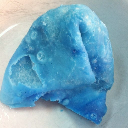

In [ ]:
output_predictions = []

sel_idx = 1521
for idx, (data_i_x, data_i_y) in enumerate(mkdataset.valid_dataset):
  pred_i = np.argmax(learner.model(data_i_x).numpy()[0])
  output_predictions.append(pred_i)
  if idx==sel_idx:
    tmp_img = data_i_x.numpy()[0]

cv2_imshow(tmp_img)

In [ ]:
#將結果寫入 csv 檔
with open("fake_predict.csv", 'w') as fw:
  fw.write('Id,Category\n')
  for i, y in enumerate(output_predictions):
    fw.write('{},{}\n'.format(i, y))

In [ ]:
!cat fake_predict.csv | head -20

Id,Category
0,4
1,2
2,0
3,4
4,0
5,0
6,8
7,0
8,0
9,0
10,0
11,0
12,2
13,0
14,0
15,0
16,0
17,0
18,5


In [ ]:
!ls fake_test/0/ | head -1522 | tail -1

04_0188.jpg


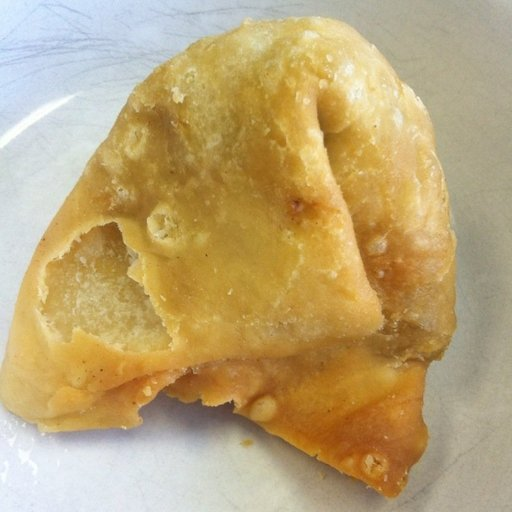

In [ ]:
tmp_img = cv2.imread("fake_test/0/04_0188.jpg")
cv2_imshow(tmp_img)

##6.2 Predict testing dataset

In [43]:
!mkdir food11_fortf_testing
!mkdir food11_fortf_testing/0
!cp food-11/testing/*.jpg food11_fortf_testing/0/

In [44]:
test_img_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    directory="food11_fortf_testing", labels='inferred', label_mode='int', 
    color_mode='rgb', batch_size=1, image_size=(128, 128), shuffle=False, seed=12345,
    validation_split=None, subset=None, interpolation='nearest', follow_links=False
)

Found 3347 files belonging to 1 classes.


In [45]:
test_x, test_y = read_tfdataset(test_img_dataset, True)
print("Size of testing data = {}".format(len(test_x)))

Size of testing data = 3347


In [ ]:
mkdataset.set_validation_dataset(test_x, test_y)

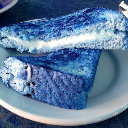

In [ ]:
output_predictions = []

sel_idx = 1872
for idx, (data_i_x, data_i_y) in enumerate(mkdataset.valid_dataset):
  pred_i = np.argmax(learner.model(data_i_x).numpy()[0])
  output_predictions.append(pred_i)
  if idx==sel_idx:
    tmp_img = data_i_x.numpy()[0]

cv2_imshow(tmp_img)

In [ ]:
#將結果寫入 csv 檔
with open("predict.csv", 'w') as fw:
  fw.write('Id,Category\n')
  for i, y in enumerate(output_predictions):
    fw.write('{},{}\n'.format(i, y))

In [ ]:
!ls food11_fortf_testing/0/ | head -1873 | tail -1

1872.jpg


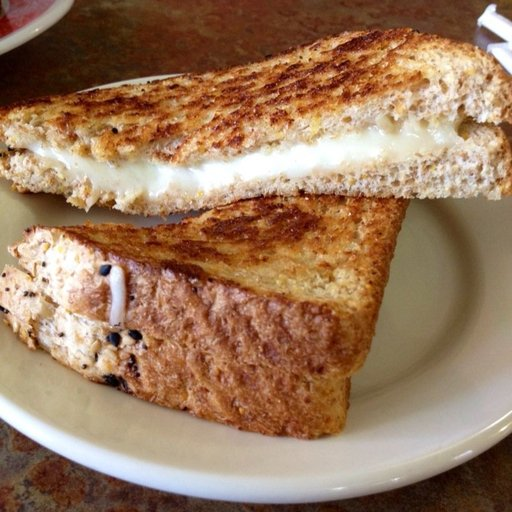

In [ ]:
tmp_img = cv2.imread("food11_fortf_testing/0/1872.jpg")
cv2_imshow(tmp_img)

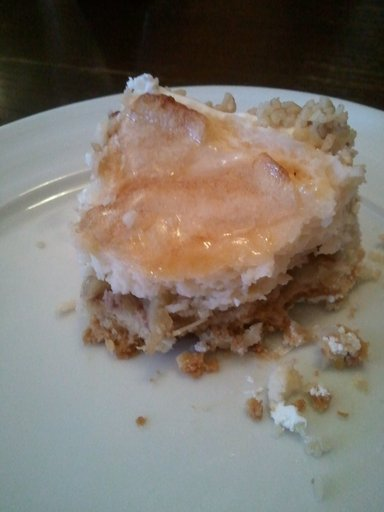

In [ ]:
tmp_img = cv2.imread("food11_fortf_testing/0/0000.jpg")
cv2_imshow(tmp_img)

In [ ]:
!cat predict.csv | head -100

Id,Category
0,2
1,10
2,3
3,2
4,5
5,3
6,4
7,5
8,2
9,2
10,2
11,2
12,0
13,10
14,5
15,4
16,9
17,4
18,5
19,9
20,5
21,5
22,1
23,3
24,2
25,8
26,2
27,4
28,4
29,5
30,2
31,9
32,2
33,2
34,5
35,2
36,5
37,10
38,10
39,2
40,6
41,2
42,1
43,2
44,5
45,1
46,10
47,3
48,5
49,9
50,10
51,1
52,3
53,3
54,0
55,8
56,5
57,9
58,6
59,2
60,5
61,4
62,2
63,3
64,10
65,2
66,1
67,9
68,4
69,10
70,5
71,5
72,5
73,8
74,9
75,0
76,0
77,0
78,9
79,9
80,4
81,2
82,9
83,2
84,8
85,2
86,4
87,4
88,4
89,0
90,1
91,0
92,0
93,9
94,0
95,6
96,2
97,2
98,6


In [ ]:
files.download('predict.csv') #score 0.65511 private: 0.65651

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#7. Model

In [29]:
class CNNModel_2DWideAndDeep(tf.keras.Model):
    def __init__(self, pic_height=128, pic_width=128, n_classes=11):
        super(CNNModel_2DWideAndDeep, self).__init__()
        self.n_classes = n_classes
 

        self.data_augmentation = tf.keras.Sequential(
            [
             #tf.keras.layers.experimental.preprocessing.RandomContrast(0.1),
             tf.keras.layers.experimental.preprocessing.RandomFlip("horizontal_and_vertical"),
             tf.keras.layers.experimental.preprocessing.RandomTranslation(height_factor=0.1, width_factor=0.1, interpolation='nearest'),
             tf.keras.layers.experimental.preprocessing.RandomRotation(0.125, interpolation="nearest"), #1/8 * 2pi
             #tf.keras.layers.experimental.preprocessing.RandomRotation(0.0625, interpolation="nearest") #, #1/16 * 2pi
             #tf.keras.layers.experimental.preprocessing.RandomZoom(height_factor=0.1, width_factor=0.1, interpolation='nearest'),
            ]
        )

        self.image2dlayers_R1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(4, 4), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)             
            ]
        )
        self.image2dlayers_R2 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=128, kernel_size=(4, 4), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )        
        self.image2dlayers_R3 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=256, kernel_size=(4, 4), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )
        self.image2dlayers_L1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=32, kernel_size=(32, 32), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )
        self.image2dlayers_LL1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(16, 16), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )
 
        self.flatLL = tf.keras.layers.Flatten()
        self.flatL = tf.keras.layers.Flatten()
        self.flatR = tf.keras.layers.Flatten()
 
        self.dropout1 = tf.keras.layers.Dropout(0.2)
        self.flatten1dlayersR = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=256, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=128, activation=tf.keras.activations.relu)
            ]
        )
        self.flatten1dlayersL = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=16, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=8, activation=tf.keras.activations.relu)
            ]
        )
 
        self.flatten1dlayersLL = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=64, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=16, activation=tf.keras.activations.relu)
            ]
        )
        self.dropout2 = tf.keras.layers.Dropout(0.2)
        #self.outputlayer = tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.relu)
        self.outputlayer = tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.linear)
        #self.outputlayer = tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.sigmoid)
 
    def call(self, input, training=False):
        local_input = input
        if training:
            local_input = self.data_augmentation(local_input)        
 
        resultR = self.image2dlayers_R1(local_input)
        resultR = self.image2dlayers_R2(resultR)
        resultR = self.image2dlayers_R3(resultR)
        resultR = self.flatR(resultR)
        resultR = self.dropout1(resultR, training=training)
        resultR = self.flatten1dlayersR(resultR)
        resultR = self.dropout2(resultR, training=training)
 
        resultL = self.image2dlayers_L1(local_input)
        resultL = self.flatL(resultL)
        resultL = self.dropout1(resultL, training=training)
        resultL = self.flatten1dlayersL(resultL)
        resultL = self.dropout2(resultL, training=training)
 
        resultLL = self.image2dlayers_LL1(local_input)
        resultLL = self.flatLL(resultLL)
        resultLL = self.dropout1(resultLL, training=training)
        resultLL = self.flatten1dlayersLL(resultLL)
        resultLL = self.dropout2(resultLL, training=training)
 
        result = tf.concat([resultR, resultL, resultLL], 1)
 
        result = self.outputlayer(result)
 
        return result

#### testing

In [ ]:
model_try = CNNModel_2DWideAndDeep()

In [ ]:
model_try(tf.expand_dims(tf.constant(train_x[0]), axis=0))

<tf.Tensor: shape=(1, 11), dtype=float32, numpy=
array([[ 0.      , 26.77701 ,  0.      ,  0.      , 12.553409,  0.      ,
        21.275871, 12.434843,  0.      , 23.192192,  0.      ]],
      dtype=float32)>

In [ ]:
model_try.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
model_try.fit(
    x=train_x, y=train_y, batch_size=64, epochs=5, verbose=1, callbacks=None,
    validation_split=0.0, validation_data=(val_x, val_y), shuffle=True, class_weight=None,
    sample_weight=None, initial_epoch=0, steps_per_epoch=None,
    validation_steps=None, validation_batch_size=1, validation_freq=1,
    max_queue_size=8, workers=1, use_multiprocessing=False
)

Epoch 1/5
155/155 [==============================] - 24s 157ms/step - loss: 2.4457 - accuracy: 0.1028 - val_loss: 2.3979 - val_accuracy: 0.1058
Epoch 2/5
155/155 [==============================] - 24s 152ms/step - loss: 2.3982 - accuracy: 0.1004 - val_loss: 2.3979 - val_accuracy: 0.1055
Epoch 3/5
155/155 [==============================] - 23s 150ms/step - loss: 2.3979 - accuracy: 0.1006 - val_loss: 2.3979 - val_accuracy: 0.1055
Epoch 4/5
155/155 [==============================] - 23s 150ms/step - loss: 2.3979 - accuracy: 0.1008 - val_loss: 2.3979 - val_accuracy: 0.1055
Epoch 5/5
155/155 [==============================] - 23s 151ms/step - loss: 2.3979 - accuracy: 0.1008 - val_loss: 2.3979 - val_accuracy: 0.1055


In [ ]:
model_try.summary()

Model: "cnn_model_2d_wide_and_deep_4"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
sequential_42 (Sequential)   (None, 128, 128, 3)       0         
_________________________________________________________________
sequential_43 (Sequential)   (None, 31, 31, 64)        3392      
_________________________________________________________________
sequential_44 (Sequential)   (None, 7, 7, 128)         131712    
_________________________________________________________________
sequential_45 (Sequential)   (None, 1, 1, 256)         525568    
_________________________________________________________________
sequential_46 (Sequential)   (None, 24, 24, 32)        98464     
_________________________________________________________________
sequential_47 (Sequential)   (None, 28, 28, 64)        49472     
_________________________________________________________________
flatten_13 (Flatten)         multiple 

#8. Training

* find parameters

In [30]:
train_val_x = np.concatenate((train_x, val_x), axis=0)
train_val_y = np.concatenate((train_y, val_y), axis=0)

In [ ]:
mkdataset2 = MkTFDataset()

In [ ]:
train_batch_size = 16

mkdataset2.init_fulltraindata(train_val_x, train_val_y, batch_size=train_batch_size, ratio=0.9)
learner = Learner(11, train_dataset=mkdataset2.train_dataset, valid_dataset=mkdataset2.valid_dataset)
learner.model = CNNModel_2DWideAndDeep(pic_height=128, pic_width=128, n_classes=11)
learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001, rho=0.9, momentum=0.0, epsilon=1e-07)

learner.num_epochs = 200
learner.num_epochs_validation = 5
learner.train()

Epoch 5 24.36 sec(s) , Loss: 1.684781, CategoricalAccurancy:0.418018, Valid Loss: 1.717523, Valid CategoricalAccurancy:0.455639
Epoch 10 23.98 sec(s) , Loss: 1.484662, CategoricalAccurancy:0.498245, Valid Loss: 1.347776, Valid CategoricalAccurancy:0.567669
Epoch 15 23.97 sec(s) , Loss: 1.373500, CategoricalAccurancy:0.536353, Valid Loss: 1.386718, Valid CategoricalAccurancy:0.618045
Epoch 20 24.04 sec(s) , Loss: 1.330752, CategoricalAccurancy:0.557413, Valid Loss: 1.210685, Valid CategoricalAccurancy:0.645113
Epoch 25 23.96 sec(s) , Loss: 1.276633, CategoricalAccurancy:0.571369, Valid Loss: 1.257409, Valid CategoricalAccurancy:0.637594
Epoch 30 23.91 sec(s) , Loss: 1.246557, CategoricalAccurancy:0.583152, Valid Loss: 1.523851, Valid CategoricalAccurancy:0.631579
Epoch 35 24.13 sec(s) , Loss: 1.221156, CategoricalAccurancy:0.600786, Valid Loss: 1.615763, Valid CategoricalAccurancy:0.702256
Epoch 40 23.95 sec(s) , Loss: 1.192628, CategoricalAccurancy:0.607638, Valid Loss: 1.067108, Valid

In [ ]:
train_batch_size = 16

mkdataset2.init_fulltraindata(train_val_x, train_val_y, batch_size=train_batch_size, ratio=0.9)
learner = Learner(11, train_dataset=mkdataset2.train_dataset, valid_dataset=mkdataset2.valid_dataset)
learner.model = CNNModel_2DWideAndDeep(pic_height=128, pic_width=128, n_classes=11)
learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001, rho=0.9, momentum=0.0, epsilon=1e-07)

learner.num_epochs = 500
learner.num_epochs_validation = 10
learner.train()

Epoch 10 24.42 sec(s) , Loss: 1.490486, CategoricalAccurancy:0.490807, Valid Loss: 1.422084, Valid CategoricalAccurancy:0.566917
Epoch 20 23.86 sec(s) , Loss: 1.328371, CategoricalAccurancy:0.547969, Valid Loss: 1.208072, Valid CategoricalAccurancy:0.630827
Epoch 30 23.82 sec(s) , Loss: 1.223590, CategoricalAccurancy:0.584740, Valid Loss: 1.162846, Valid CategoricalAccurancy:0.632331
Epoch 40 23.89 sec(s) , Loss: 1.172897, CategoricalAccurancy:0.608223, Valid Loss: 0.880827, Valid CategoricalAccurancy:0.743609
Epoch 50 23.83 sec(s) , Loss: 1.135946, CategoricalAccurancy:0.629784, Valid Loss: 1.035316, Valid CategoricalAccurancy:0.710526
Epoch 60 23.81 sec(s) , Loss: 1.122152, CategoricalAccurancy:0.634882, Valid Loss: 0.790314, Valid CategoricalAccurancy:0.770677
Epoch 70 23.88 sec(s) , Loss: 1.083293, CategoricalAccurancy:0.640398, Valid Loss: 1.329132, Valid CategoricalAccurancy:0.599248
Epoch 80 23.83 sec(s) , Loss: 1.073370, CategoricalAccurancy:0.651178, Valid Loss: 0.955846, Vali

* train dataset_train + dataset_valid

In [31]:
train_batch_size = 16
mkdataset2 = MkTFDataset()
mkdataset2.set_training_dataset(train_val_x, train_val_y, batch_size=train_batch_size)
mkdataset2.set_validation_dataset(val_x, val_y)

learner = Learner(11, train_dataset=mkdataset2.train_dataset, valid_dataset=mkdataset2.valid_dataset)
learner.model = CNNModel_2DWideAndDeep(pic_height=128, pic_width=128, n_classes=11)
learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001, rho=0.9, momentum=0.0, epsilon=1e-07)

learner.num_epochs = 120 #360 #分段
learner.num_epochs_validation = 10
learner.train()

Epoch 10 29.92 sec(s) , Loss: 1.456132, CategoricalAccurancy:0.501128, Valid Loss: 1.288208, Valid CategoricalAccurancy:0.582507
Epoch 20 29.52 sec(s) , Loss: 1.279282, CategoricalAccurancy:0.571751, Valid Loss: 1.179624, Valid CategoricalAccurancy:0.645481
Epoch 30 29.55 sec(s) , Loss: 1.213923, CategoricalAccurancy:0.597398, Valid Loss: 1.112431, Valid CategoricalAccurancy:0.649563
Epoch 40 29.48 sec(s) , Loss: 1.166000, CategoricalAccurancy:0.614621, Valid Loss: 1.234151, Valid CategoricalAccurancy:0.597085
Epoch 50 29.46 sec(s) , Loss: 1.139068, CategoricalAccurancy:0.625451, Valid Loss: 1.195148, Valid CategoricalAccurancy:0.660058
Epoch 60 29.49 sec(s) , Loss: 1.093384, CategoricalAccurancy:0.638312, Valid Loss: 0.919433, Valid CategoricalAccurancy:0.700583
Epoch 70 29.48 sec(s) , Loss: 1.075380, CategoricalAccurancy:0.648992, Valid Loss: 1.002021, Valid CategoricalAccurancy:0.679300
Epoch 80 29.45 sec(s) , Loss: 1.044974, CategoricalAccurancy:0.657341, Valid Loss: 0.936032, Vali

In [32]:
learner.num_epochs = 120 #360 #分段-2
learner.num_epochs_validation = 10
learner.train()

Epoch 10 29.38 sec(s) , Loss: 0.959880, CategoricalAccurancy:0.696300, Valid Loss: 0.753741, Valid CategoricalAccurancy:0.761808
Epoch 20 29.41 sec(s) , Loss: 0.957585, CategoricalAccurancy:0.695247, Valid Loss: 0.827934, Valid CategoricalAccurancy:0.736152
Epoch 30 29.46 sec(s) , Loss: 0.922204, CategoricalAccurancy:0.705927, Valid Loss: 0.724433, Valid CategoricalAccurancy:0.772012
Epoch 40 29.45 sec(s) , Loss: 0.920435, CategoricalAccurancy:0.709988, Valid Loss: 0.734043, Valid CategoricalAccurancy:0.773761
Epoch 50 29.46 sec(s) , Loss: 0.893662, CategoricalAccurancy:0.718412, Valid Loss: 0.700581, Valid CategoricalAccurancy:0.776676
Epoch 60 29.41 sec(s) , Loss: 0.906410, CategoricalAccurancy:0.717810, Valid Loss: 0.712858, Valid CategoricalAccurancy:0.781050
Epoch 70 29.43 sec(s) , Loss: 0.889691, CategoricalAccurancy:0.720668, Valid Loss: 0.729372, Valid CategoricalAccurancy:0.771429
Epoch 80 29.41 sec(s) , Loss: 0.887460, CategoricalAccurancy:0.724579, Valid Loss: 0.903977, Vali

In [37]:
learner.num_epochs = 120 #360 #分段-3
learner.num_epochs_validation = 10
learner.train()

Epoch 10 29.50 sec(s) , Loss: 0.806884, CategoricalAccurancy:0.746992, Valid Loss: 0.681052, Valid CategoricalAccurancy:0.800292
Epoch 20 29.43 sec(s) , Loss: 0.813103, CategoricalAccurancy:0.752407, Valid Loss: 0.778271, Valid CategoricalAccurancy:0.763848
Epoch 30 29.41 sec(s) , Loss: 0.807218, CategoricalAccurancy:0.751955, Valid Loss: 0.801127, Valid CategoricalAccurancy:0.748105
Epoch 40 29.42 sec(s) , Loss: 0.794428, CategoricalAccurancy:0.755942, Valid Loss: 0.840985, Valid CategoricalAccurancy:0.744315
Epoch 50 29.44 sec(s) , Loss: 0.779977, CategoricalAccurancy:0.759477, Valid Loss: 0.918983, Valid CategoricalAccurancy:0.771137
Epoch 60 29.42 sec(s) , Loss: 0.774129, CategoricalAccurancy:0.764215, Valid Loss: 0.598968, Valid CategoricalAccurancy:0.809913
Epoch 70 29.38 sec(s) , Loss: 0.769372, CategoricalAccurancy:0.764816, Valid Loss: 0.710308, Valid CategoricalAccurancy:0.788921
Epoch 80 29.48 sec(s) , Loss: 0.750270, CategoricalAccurancy:0.768502, Valid Loss: 0.652410, Vali

#### details: parameters (2DWideAndDeep)

"""


In [ ]:
"""
Epoch 10 24.42 sec(s) , Loss: 1.490486, CategoricalAccurancy:0.490807, Valid Loss: 1.422084, Valid CategoricalAccurancy:0.566917
Epoch 20 23.86 sec(s) , Loss: 1.328371, CategoricalAccurancy:0.547969, Valid Loss: 1.208072, Valid CategoricalAccurancy:0.630827
Epoch 30 23.82 sec(s) , Loss: 1.223590, CategoricalAccurancy:0.584740, Valid Loss: 1.162846, Valid CategoricalAccurancy:0.632331
Epoch 40 23.89 sec(s) , Loss: 1.172897, CategoricalAccurancy:0.608223, Valid Loss: 0.880827, Valid CategoricalAccurancy:0.743609
Epoch 50 23.83 sec(s) , Loss: 1.135946, CategoricalAccurancy:0.629784, Valid Loss: 1.035316, Valid CategoricalAccurancy:0.710526
Epoch 60 23.81 sec(s) , Loss: 1.122152, CategoricalAccurancy:0.634882, Valid Loss: 0.790314, Valid CategoricalAccurancy:0.770677
Epoch 70 23.88 sec(s) , Loss: 1.083293, CategoricalAccurancy:0.640398, Valid Loss: 1.329132, Valid CategoricalAccurancy:0.599248
Epoch 80 23.83 sec(s) , Loss: 1.073370, CategoricalAccurancy:0.651178, Valid Loss: 0.955846, Valid CategoricalAccurancy:0.745113
Epoch 90 23.79 sec(s) , Loss: 1.050269, CategoricalAccurancy:0.655524, Valid Loss: 0.918564, Valid CategoricalAccurancy:0.719549
Epoch 100 23.74 sec(s) , Loss: 1.044336, CategoricalAccurancy:0.664382, Valid Loss: 0.981166, Valid CategoricalAccurancy:0.730075
Epoch 110 23.81 sec(s) , Loss: 1.022977, CategoricalAccurancy:0.673659, Valid Loss: 0.904112, Valid CategoricalAccurancy:0.742105
Epoch 120 23.82 sec(s) , Loss: 0.993630, CategoricalAccurancy:0.676166, Valid Loss: 1.471644, Valid CategoricalAccurancy:0.650376
Epoch 130 23.79 sec(s) , Loss: 0.976375, CategoricalAccurancy:0.688033, Valid Loss: 0.857404, Valid CategoricalAccurancy:0.776692
Epoch 140 23.77 sec(s) , Loss: 0.971616, CategoricalAccurancy:0.689453, Valid Loss: 0.824888, Valid CategoricalAccurancy:0.790977
Epoch 150 23.75 sec(s) , Loss: 0.967700, CategoricalAccurancy:0.689955, Valid Loss: 1.359788, Valid CategoricalAccurancy:0.685714
Epoch 160 23.80 sec(s) , Loss: 0.949956, CategoricalAccurancy:0.695471, Valid Loss: 1.037996, Valid CategoricalAccurancy:0.729323
Epoch 170 23.79 sec(s) , Loss: 0.928064, CategoricalAccurancy:0.708340, Valid Loss: 1.299017, Valid CategoricalAccurancy:0.681203
Epoch 180 23.76 sec(s) , Loss: 0.904027, CategoricalAccurancy:0.712686, Valid Loss: 1.020878, Valid CategoricalAccurancy:0.806015
Epoch 190 23.81 sec(s) , Loss: 0.891874, CategoricalAccurancy:0.712937, Valid Loss: 1.125616, Valid CategoricalAccurancy:0.769173
Epoch 200 23.84 sec(s) , Loss: 0.897028, CategoricalAccurancy:0.716948, Valid Loss: 1.266270, Valid CategoricalAccurancy:0.715789
Epoch 210 23.83 sec(s) , Loss: 0.890978, CategoricalAccurancy:0.715694, Valid Loss: 1.564812, Valid CategoricalAccurancy:0.734586
Epoch 220 23.76 sec(s) , Loss: 0.891644, CategoricalAccurancy:0.716447, Valid Loss: 1.119963, Valid CategoricalAccurancy:0.773684
Epoch 230 23.78 sec(s) , Loss: 0.860188, CategoricalAccurancy:0.732993, Valid Loss: 1.229673, Valid CategoricalAccurancy:0.724060
Epoch 240 23.75 sec(s) , Loss: 0.863048, CategoricalAccurancy:0.733161, Valid Loss: 1.024747, Valid CategoricalAccurancy:0.769173
Epoch 250 23.87 sec(s) , Loss: 0.853206, CategoricalAccurancy:0.734748, Valid Loss: 2.331319, Valid CategoricalAccurancy:0.675940
Epoch 260 23.84 sec(s) , Loss: 0.839317, CategoricalAccurancy:0.732492, Valid Loss: 0.896192, Valid CategoricalAccurancy:0.805263
Epoch 270 23.72 sec(s) , Loss: 0.840631, CategoricalAccurancy:0.732910, Valid Loss: 1.406245, Valid CategoricalAccurancy:0.710526
Epoch 280 23.81 sec(s) , Loss: 0.813500, CategoricalAccurancy:0.746866, Valid Loss: 0.946643, Valid CategoricalAccurancy:0.809023
Epoch 290 23.78 sec(s) , Loss: 0.811323, CategoricalAccurancy:0.743774, Valid Loss: 1.074213, Valid CategoricalAccurancy:0.812782
Epoch 300 23.81 sec(s) , Loss: 0.810576, CategoricalAccurancy:0.746448, Valid Loss: 0.839494, Valid CategoricalAccurancy:0.821053
Epoch 310 23.73 sec(s) , Loss: 0.825079, CategoricalAccurancy:0.749206, Valid Loss: 0.976649, Valid CategoricalAccurancy:0.793233
Epoch 320 23.73 sec(s) , Loss: 0.803530, CategoricalAccurancy:0.754471, Valid Loss: 1.475406, Valid CategoricalAccurancy:0.765414
Epoch 330 23.73 sec(s) , Loss: 0.803297, CategoricalAccurancy:0.751797, Valid Loss: 1.179256, Valid CategoricalAccurancy:0.806767
Epoch 340 23.79 sec(s) , Loss: 0.765392, CategoricalAccurancy:0.758232, Valid Loss: 1.069124, Valid CategoricalAccurancy:0.814286
Epoch 350 23.76 sec(s) , Loss: 0.775389, CategoricalAccurancy:0.758566, Valid Loss: 1.088966, Valid CategoricalAccurancy:0.822556
*Epoch 360 23.84 sec(s) , Loss: 0.769073, CategoricalAccurancy:0.769764, Valid Loss: 0.855123, Valid CategoricalAccurancy:0.836842
Epoch 370 23.76 sec(s) , Loss: 0.765062, CategoricalAccurancy:0.769931, Valid Loss: 1.431435, Valid CategoricalAccurancy:0.785714
Epoch 380 23.85 sec(s) , Loss: 0.742966, CategoricalAccurancy:0.776533, Valid Loss: 1.175069, Valid CategoricalAccurancy:0.765414
Epoch 390 23.75 sec(s) , Loss: 0.731808, CategoricalAccurancy:0.778372, Valid Loss: 1.735238, Valid CategoricalAccurancy:0.712782
Epoch 400 23.98 sec(s) , Loss: 0.706359, CategoricalAccurancy:0.781715, Valid Loss: 1.344408, Valid CategoricalAccurancy:0.793233
Epoch 410 23.79 sec(s) , Loss: 0.737960, CategoricalAccurancy:0.781046, Valid Loss: 1.193199, Valid CategoricalAccurancy:0.802256
Epoch 420 23.76 sec(s) , Loss: 0.725112, CategoricalAccurancy:0.776116, Valid Loss: 1.312136, Valid CategoricalAccurancy:0.829323
Epoch 430 23.77 sec(s) , Loss: 0.702097, CategoricalAccurancy:0.789905, Valid Loss: 1.491720, Valid CategoricalAccurancy:0.780451
Epoch 440 23.72 sec(s) , Loss: 0.705072, CategoricalAccurancy:0.788317, Valid Loss: 2.367616, Valid CategoricalAccurancy:0.728571
Epoch 450 23.73 sec(s) , Loss: 0.703812, CategoricalAccurancy:0.789487, Valid Loss: 2.080361, Valid CategoricalAccurancy:0.760150
Epoch 460 23.82 sec(s) , Loss: 0.701942, CategoricalAccurancy:0.789236, Valid Loss: 2.267590, Valid CategoricalAccurancy:0.808271
Epoch 470 23.86 sec(s) , Loss: 0.699436, CategoricalAccurancy:0.796172, Valid Loss: 1.776466, Valid CategoricalAccurancy:0.790226
Epoch 480 23.82 sec(s) , Loss: 0.695811, CategoricalAccurancy:0.796172, Valid Loss: 2.114162, Valid CategoricalAccurancy:0.781203
Epoch 490 23.72 sec(s) , Loss: 0.686623, CategoricalAccurancy:0.796423, Valid Loss: 1.887694, Valid CategoricalAccurancy:0.821805
Epoch 500 23.78 sec(s) , Loss: 0.698553, CategoricalAccurancy:0.793833, Valid Loss: 1.446681, Valid CategoricalAccurancy:0.796241
"""

##### model

```
class CNNModel_2DWideAndDeep(tf.keras.Model):
    def __init__(self, pic_height=128, pic_width=128, n_classes=11):
        super(CNNModel_2DWideAndDeep, self).__init__()
        self.n_classes = n_classes
 

        self.data_augmentation = tf.keras.Sequential(
            [
             #tf.keras.layers.experimental.preprocessing.RandomContrast(0.1),
             tf.keras.layers.experimental.preprocessing.RandomFlip("horizontal_and_vertical"),
             tf.keras.layers.experimental.preprocessing.RandomTranslation(height_factor=0.1, width_factor=0.1, interpolation='nearest'),
             tf.keras.layers.experimental.preprocessing.RandomRotation(0.125, interpolation="nearest"), #1/8 * 2pi
             #tf.keras.layers.experimental.preprocessing.RandomRotation(0.0625, interpolation="nearest") #, #1/16 * 2pi
             #tf.keras.layers.experimental.preprocessing.RandomZoom(height_factor=0.1, width_factor=0.1, interpolation='nearest'),
            ]
        )

        self.image2dlayers_R1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(4, 4), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)             
            ]
        )
        self.image2dlayers_R2 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=128, kernel_size=(4, 4), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )        
        self.image2dlayers_R3 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=256, kernel_size=(4, 4), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )
        self.image2dlayers_L1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=32, kernel_size=(32, 32), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )
        self.image2dlayers_LL1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(16, 16), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )
 
        self.flatLL = tf.keras.layers.Flatten()
        self.flatL = tf.keras.layers.Flatten()
        self.flatR = tf.keras.layers.Flatten()
 
        self.dropout1 = tf.keras.layers.Dropout(0.2)
        self.flatten1dlayersR = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=256, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=128, activation=tf.keras.activations.relu)
            ]
        )
        self.flatten1dlayersL = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=16, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=8, activation=tf.keras.activations.relu)
            ]
        )
 
        self.flatten1dlayersLL = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=64, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=16, activation=tf.keras.activations.relu)
            ]
        )
        self.dropout2 = tf.keras.layers.Dropout(0.2)
        self.outputlayer = tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.relu)
        #self.outputlayer = tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.linear)
        #self.outputlayer = tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.sigmoid)
 
    def call(self, input, training=False):
        local_input = input
        if training:
            local_input = self.data_augmentation(local_input)        
 
        resultR = self.image2dlayers_R1(local_input)
        resultR = self.image2dlayers_R2(resultR)
        resultR = self.image2dlayers_R3(resultR)
        resultR = self.flatR(resultR)
        resultR = self.dropout1(resultR, training=training)
        resultR = self.flatten1dlayersR(resultR)
        resultR = self.dropout2(resultR, training=training)
 
        resultL = self.image2dlayers_L1(local_input)
        resultL = self.flatL(resultL)
        resultL = self.dropout1(resultL, training=training)
        resultL = self.flatten1dlayersL(resultL)
        resultL = self.dropout2(resultL, training=training)
 
        resultLL = self.image2dlayers_LL1(local_input)
        resultLL = self.flatLL(resultLL)
        resultLL = self.dropout1(resultLL, training=training)
        resultLL = self.flatten1dlayersLL(resultLL)
        resultLL = self.dropout2(resultLL, training=training)
 
        result = tf.concat([resultR, resultL, resultLL], 1)
 
        result = self.outputlayer(result)
 
        return result
```

##### result

In [ ]:
#train_batch_size = 64
#mkdataset2.init_fulltraindata(train_val_x, train_val_y, batch_size=train_batch_size, ratio=0.9)
#learner = Learner(11, train_dataset=mkdataset2.train_dataset, valid_dataset=mkdataset2.valid_dataset)
#learner.model = CNNModel_2DWideAndDeep(pic_height=128, pic_width=128, n_classes=11)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 5 20.52 sec(s) , Loss: 1.759962, CategoricalAccurancy:0.388183, Valid Loss: 2.232028, Valid CategoricalAccurancy:0.434586
Epoch 10 20.31 sec(s) , Loss: 1.503382, CategoricalAccurancy:0.483955, Valid Loss: 1.562595, Valid CategoricalAccurancy:0.509774
"""

#train_batch_size = 32
"""
Epoch 5 20.95 sec(s) , Loss: 1.716500, CategoricalAccurancy:0.402223, Valid Loss: 3.043812, Valid CategoricalAccurancy:0.360902
Epoch 10 20.93 sec(s) , Loss: 1.482140, CategoricalAccurancy:0.486629, Valid Loss: 1.433631, Valid CategoricalAccurancy:0.562406
"""

#train_batch_size = 16
"""
Epoch 5 22.80 sec(s) , Loss: 1.683947, CategoricalAccurancy:0.415761, Valid Loss: 1.501998, Valid CategoricalAccurancy:0.534586
Epoch 10 22.57 sec(s) , Loss: 1.501542, CategoricalAccurancy:0.486963, Valid Loss: 1.364111, Valid CategoricalAccurancy:0.554887
"""

#train_batch_size = 8
"""
Epoch 5 25.59 sec(s) , Loss: 1.757702, CategoricalAccurancy:0.395287, Valid Loss: 1.974916, Valid CategoricalAccurancy:0.393233
Epoch 10 25.44 sec(s) , Loss: 1.719476, CategoricalAccurancy:0.424453, Valid Loss: 1.868746, Valid CategoricalAccurancy:0.568421
"""

In [ ]:
#train_batch_size = 16
#mkdataset2.init_fulltraindata(train_val_x, train_val_y, batch_size=train_batch_size, ratio=0.9)
#learner = Learner(11, train_dataset=mkdataset2.train_dataset, valid_dataset=mkdataset2.valid_dataset)
#learner.model = CNNModel_2DWideAndDeep(pic_height=128, pic_width=128, n_classes=11)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 5 22.59 sec(s) , Loss: 1.738666, CategoricalAccurancy:0.412419, Valid Loss: 2.437743, Valid CategoricalAccurancy:0.422556
Epoch 10 22.46 sec(s) , Loss: 1.660426, CategoricalAccurancy:0.449440, Valid Loss: 1.629307, Valid CategoricalAccurancy:0.484962
"""

#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 5 23.23 sec(s) , Loss: 2.030170, CategoricalAccurancy:0.290740, Valid Loss: 2.201362, Valid CategoricalAccurancy:0.275188
Epoch 10 23.08 sec(s) , Loss: 1.901433, CategoricalAccurancy:0.337707, Valid Loss: 1.984981, Valid CategoricalAccurancy:0.333835
"""

#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.8, beta_2=0.5, epsilon=1e-09)
"""
Epoch 5 22.65 sec(s) , Loss: 1.758721, CategoricalAccurancy:0.401387, Valid Loss: 2.254565, Valid CategoricalAccurancy:0.415038
Epoch 10 22.46 sec(s) , Loss: 1.522107, CategoricalAccurancy:0.479358, Valid Loss: 1.706126, Valid CategoricalAccurancy:0.469925
"""

#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 5 22.73 sec(s) , Loss: 1.715170, CategoricalAccurancy:0.403811, Valid Loss: 1.779296, Valid CategoricalAccurancy:0.413534
Epoch 10 22.53 sec(s) , Loss: 1.508035, CategoricalAccurancy:0.491309, Valid Loss: 1.605574, Valid CategoricalAccurancy:0.487218
"""

In [ ]:
#train_batch_size = 16
#mkdataset2.init_fulltraindata(train_val_x, train_val_y, batch_size=train_batch_size, ratio=0.9)
#learner = Learner(11, train_dataset=mkdataset2.train_dataset, valid_dataset=mkdataset2.valid_dataset)
#learner.model = CNNModel_2DWideAndDeep(pic_height=128, pic_width=128, n_classes=11)
#learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.001, rho=0.9, momentum=0.0, epsilon=1e-07)
"""
Epoch 5 23.92 sec(s) , Loss: 1.657680, CategoricalAccurancy:0.434481, Valid Loss: 1.841837, Valid CategoricalAccurancy:0.387970
Epoch 10 23.96 sec(s) , Loss: 1.569381, CategoricalAccurancy:0.484707, Valid Loss: 3.523954, Valid CategoricalAccurancy:0.375188
"""

#learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001, rho=0.9, momentum=0.0, epsilon=1e-07)
"""
Epoch 5 24.17 sec(s) , Loss: 1.704818, CategoricalAccurancy:0.409995, Valid Loss: 1.905653, Valid CategoricalAccurancy:0.424812
Epoch 10 23.98 sec(s) , Loss: 1.497911, CategoricalAccurancy:0.489303, Valid Loss: 1.589146, Valid CategoricalAccurancy:0.580451
"""
#learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001, rho=0.8, momentum=0.0, epsilon=1e-07)
"""
Epoch 5 24.25 sec(s) , Loss: 1.760436, CategoricalAccurancy:0.392445, Valid Loss: 1.760436, Valid CategoricalAccurancy:0.432331
Epoch 10 24.02 sec(s) , Loss: 1.559358, CategoricalAccurancy:0.477352, Valid Loss: 2.129482, Valid CategoricalAccurancy:0.473684
"""

#learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001, rho=0.7, momentum=0.0, epsilon=1e-07)
"""
Epoch 5 24.26 sec(s) , Loss: 1.767471, CategoricalAccurancy:0.392027, Valid Loss: 2.083949, Valid CategoricalAccurancy:0.430075
Epoch 10 24.11 sec(s) , Loss: 1.594281, CategoricalAccurancy:0.464566, Valid Loss: 1.972147, Valid CategoricalAccurancy:0.499248
"""

#learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001, rho=0.7, momentum=0.2, epsilon=1e-07)
"""
Epoch 5 23.03 sec(s) , Loss: 1.724160, CategoricalAccurancy:0.404897, Valid Loss: 1.923158, Valid CategoricalAccurancy:0.409774
Epoch 10 22.95 sec(s) , Loss: 1.541820, CategoricalAccurancy:0.475013, Valid Loss: 1.429320, Valid CategoricalAccurancy:0.567669
"""
#learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001, rho=0.7, momentum=0.2, epsilon=1e-09)
"""
Epoch 5 23.12 sec(s) , Loss: 1.754452, CategoricalAccurancy:0.404479, Valid Loss: 1.747446, Valid CategoricalAccurancy:0.446617
Epoch 10 22.94 sec(s) , Loss: 1.542942, CategoricalAccurancy:0.481447, Valid Loss: 2.510690, Valid CategoricalAccurancy:0.512782
"""

In [ ]:
#train_batch_size = 16
#mkdataset2.init_fulltraindata(train_val_x, train_val_y, batch_size=train_batch_size, ratio=0.9)
#learner = Learner(11, train_dataset=mkdataset2.train_dataset, valid_dataset=mkdataset2.valid_dataset)
#learner.model = CNNModel_2DWideAndDeep(pic_height=128, pic_width=128, n_classes=11)
#learner.optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001, rho=0.9, momentum=0.0, epsilon=1e-07)
"""
Epoch 5 24.36 sec(s) , Loss: 1.684781, CategoricalAccurancy:0.418018, Valid Loss: 1.717523, Valid CategoricalAccurancy:0.455639
Epoch 10 23.98 sec(s) , Loss: 1.484662, CategoricalAccurancy:0.498245, Valid Loss: 1.347776, Valid CategoricalAccurancy:0.567669
Epoch 15 23.97 sec(s) , Loss: 1.373500, CategoricalAccurancy:0.536353, Valid Loss: 1.386718, Valid CategoricalAccurancy:0.618045
Epoch 20 24.04 sec(s) , Loss: 1.330752, CategoricalAccurancy:0.557413, Valid Loss: 1.210685, Valid CategoricalAccurancy:0.645113
Epoch 25 23.96 sec(s) , Loss: 1.276633, CategoricalAccurancy:0.571369, Valid Loss: 1.257409, Valid CategoricalAccurancy:0.637594
Epoch 30 23.91 sec(s) , Loss: 1.246557, CategoricalAccurancy:0.583152, Valid Loss: 1.523851, Valid CategoricalAccurancy:0.631579
Epoch 35 24.13 sec(s) , Loss: 1.221156, CategoricalAccurancy:0.600786, Valid Loss: 1.615763, Valid CategoricalAccurancy:0.702256
Epoch 40 23.95 sec(s) , Loss: 1.192628, CategoricalAccurancy:0.607638, Valid Loss: 1.067108, Valid CategoricalAccurancy:0.679699
Epoch 45 23.97 sec(s) , Loss: 1.180333, CategoricalAccurancy:0.609143, Valid Loss: 1.085092, Valid CategoricalAccurancy:0.696992
Epoch 50 23.89 sec(s) , Loss: 1.164644, CategoricalAccurancy:0.615410, Valid Loss: 1.028498, Valid CategoricalAccurancy:0.715789
Epoch 55 23.84 sec(s) , Loss: 1.153171, CategoricalAccurancy:0.626358, Valid Loss: 1.343788, Valid CategoricalAccurancy:0.679699
Epoch 60 23.86 sec(s) , Loss: 1.134132, CategoricalAccurancy:0.626024, Valid Loss: 1.015813, Valid CategoricalAccurancy:0.713534
Epoch 65 23.87 sec(s) , Loss: 1.103112, CategoricalAccurancy:0.645496, Valid Loss: 0.970560, Valid CategoricalAccurancy:0.733835
Epoch 70 23.83 sec(s) , Loss: 1.100207, CategoricalAccurancy:0.644911, Valid Loss: 1.070029, Valid CategoricalAccurancy:0.717293
Epoch 75 23.86 sec(s) , Loss: 1.094463, CategoricalAccurancy:0.638309, Valid Loss: 1.084966, Valid CategoricalAccurancy:0.666917
Epoch 80 23.84 sec(s) , Loss: 1.068530, CategoricalAccurancy:0.658031, Valid Loss: 0.994527, Valid CategoricalAccurancy:0.706767
Epoch 85 23.80 sec(s) , Loss: 1.057147, CategoricalAccurancy:0.654688, Valid Loss: 1.120005, Valid CategoricalAccurancy:0.712782
Epoch 90 23.83 sec(s) , Loss: 1.047317, CategoricalAccurancy:0.652599, Valid Loss: 1.011130, Valid CategoricalAccurancy:0.758647
Epoch 95 23.86 sec(s) , Loss: 1.043730, CategoricalAccurancy:0.657363, Valid Loss: 1.710899, Valid CategoricalAccurancy:0.636842
Epoch 100 23.84 sec(s) , Loss: 1.029720, CategoricalAccurancy:0.666472, Valid Loss: 1.353848, Valid CategoricalAccurancy:0.721804
Epoch 105 23.82 sec(s) , Loss: 1.018109, CategoricalAccurancy:0.667558, Valid Loss: 1.376622, Valid CategoricalAccurancy:0.649624
Epoch 110 23.86 sec(s) , Loss: 1.016392, CategoricalAccurancy:0.671653, Valid Loss: 1.015836, Valid CategoricalAccurancy:0.754887
Epoch 115 23.89 sec(s) , Loss: 1.007719, CategoricalAccurancy:0.679341, Valid Loss: 0.970073, Valid CategoricalAccurancy:0.737594
Epoch 120 23.89 sec(s) , Loss: 1.001823, CategoricalAccurancy:0.679926, Valid Loss: 0.955662, Valid CategoricalAccurancy:0.744361
Epoch 125 23.82 sec(s) , Loss: 0.996725, CategoricalAccurancy:0.681681, Valid Loss: 0.847985, Valid CategoricalAccurancy:0.765414
Epoch 130 23.82 sec(s) , Loss: 0.964917, CategoricalAccurancy:0.684021, Valid Loss: 1.174358, Valid CategoricalAccurancy:0.722556
Epoch 135 23.85 sec(s) , Loss: 0.966189, CategoricalAccurancy:0.686027, Valid Loss: 1.050151, Valid CategoricalAccurancy:0.706767
Epoch 140 23.84 sec(s) , Loss: 0.954398, CategoricalAccurancy:0.689955, Valid Loss: 0.747587, Valid CategoricalAccurancy:0.810526
Epoch 145 23.78 sec(s) , Loss: 0.951913, CategoricalAccurancy:0.694885, Valid Loss: 0.869914, Valid CategoricalAccurancy:0.757143
Epoch 150 23.80 sec(s) , Loss: 0.947088, CategoricalAccurancy:0.692546, Valid Loss: 0.820407, Valid CategoricalAccurancy:0.788722
Epoch 155 23.79 sec(s) , Loss: 0.947308, CategoricalAccurancy:0.690707, Valid Loss: 1.388561, Valid CategoricalAccurancy:0.658647
Epoch 160 23.81 sec(s) , Loss: 0.919038, CategoricalAccurancy:0.702323, Valid Loss: 2.081457, Valid CategoricalAccurancy:0.738346
Epoch 165 23.76 sec(s) , Loss: 0.952080, CategoricalAccurancy:0.694802, Valid Loss: 2.249280, Valid CategoricalAccurancy:0.557895
Epoch 170 23.80 sec(s) , Loss: 0.920343, CategoricalAccurancy:0.703410, Valid Loss: 1.147166, Valid CategoricalAccurancy:0.696992
Epoch 175 23.78 sec(s) , Loss: 0.914691, CategoricalAccurancy:0.706752, Valid Loss: 0.923799, Valid CategoricalAccurancy:0.778947
Epoch 180 23.76 sec(s) , Loss: 0.932888, CategoricalAccurancy:0.701905, Valid Loss: 0.980369, Valid CategoricalAccurancy:0.794737
Epoch 185 23.75 sec(s) , Loss: 0.920430, CategoricalAccurancy:0.708173, Valid Loss: 1.258725, Valid CategoricalAccurancy:0.773684
Epoch 190 23.77 sec(s) , Loss: 0.894822, CategoricalAccurancy:0.711182, Valid Loss: 1.143553, Valid CategoricalAccurancy:0.767669
Epoch 195 23.84 sec(s) , Loss: 0.888464, CategoricalAccurancy:0.715778, Valid Loss: 1.165821, Valid CategoricalAccurancy:0.711278
Epoch 200 23.73 sec(s) , Loss: 0.895071, CategoricalAccurancy:0.718452, Valid Loss: 1.115052, Valid CategoricalAccurancy:0.744361
"""

#### details: paramaters (concat 3 types)

##### model


```
class CNNModel_Try(tf.keras.Model):
    def __init__(self, pic_height=128, pic_width=128, n_classes=11):
        super(CNNModel_Try, self).__init__()
        self.n_classes = n_classes

        #training with Flip and Rotation , but slowly...
        self.data_augmentation = tf.keras.Sequential(
            [
             tf.keras.layers.experimental.preprocessing.RandomFlip("horizontal_and_vertical"),
             tf.keras.layers.experimental.preprocessing.RandomRotation(0.125, interpolation="nearest") #1/8 * 2pi
            ]
        )
        #to check it with basic_model
        self.image2dlayers_R1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(4, 4), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)             
            ]
        )
        self.image2dlayers_R2 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=128, kernel_size=(4, 4), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )        
        self.image2dlayers_R3 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=256, kernel_size=(4, 4), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )
        self.image2dlayers_L1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=32, kernel_size=(32, 32), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )
        self.image2dlayers_LL1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(16, 16), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(4)
            ]
        )

        self.flatLL = tf.keras.layers.Flatten()
        self.flatL = tf.keras.layers.Flatten()
        self.flatR = tf.keras.layers.Flatten()

        self.dropout1 = tf.keras.layers.Dropout(0.2)
        self.flatten1dlayersR = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=256, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=128, activation=tf.keras.activations.relu)
            ]
        )
        self.flatten1dlayersL = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=16, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=8, activation=tf.keras.activations.relu)
            ]
        )

        self.flatten1dlayersLL = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=64, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=16, activation=tf.keras.activations.relu)
            ]
        )
        self.dropout2 = tf.keras.layers.Dropout(0.2)
        self.outputlayer = tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.linear)

    def call(self, input, training=False):
        local_input = input
        if training:
            local_input = self.data_augmentation(local_input)        

        resultR = self.image2dlayers_R1(local_input)
        resultR = self.image2dlayers_R2(resultR)
        resultR = self.image2dlayers_R3(resultR)
        resultR = self.flatR(resultR)
        resultR = self.dropout1(resultR, training=training)
        resultR = self.flatten1dlayersR(resultR)
        resultR = self.dropout2(resultR, training=training)

        resultL = self.image2dlayers_L1(local_input)
        resultL = self.flatL(resultL)
        resultL = self.dropout1(resultL, training=training)
        resultL = self.flatten1dlayersL(resultL)
        resultL = self.dropout2(resultL, training=training)

        resultLL = self.image2dlayers_LL1(local_input)
        resultLL = self.flatLL(resultLL)
        resultLL = self.dropout1(resultLL, training=training)
        resultLL = self.flatten1dlayersLL(resultLL)
        resultLL = self.dropout2(resultLL, training=training)

        result = tf.concat([resultR, resultL, resultLL], 1)
        #result = tf.concat([resultR, resultL], 1)
        #result = tf.concat([resultR], 1)
        
        result = self.outputlayer(result)

        return result
```

In [33]:
learner.model.get_weights()

[array([[[[-7.31005594e-02,  4.32902239e-02,  3.17185074e-02, ...,
            1.19871618e-02, -2.09295265e-02,  9.22997966e-02],
          [ 4.40119579e-02, -3.98298306e-03,  7.94795621e-03, ...,
           -1.81712676e-02,  2.44135726e-02,  5.68180270e-02],
          [ 3.28909308e-02, -2.45222691e-02,  2.11202842e-03, ...,
           -8.85220766e-02, -4.20974335e-03,  1.13795258e-01]],
 
         [[ 3.33662666e-02, -8.04530680e-02,  2.52803471e-02, ...,
            2.14569233e-02,  3.94630469e-02, -2.89574079e-02],
          [ 2.11609155e-02,  7.70070702e-02, -1.57176647e-02, ...,
           -1.00345559e-01,  1.80551177e-03, -2.31323931e-02],
          [-2.84541231e-02,  5.00496700e-02,  6.91030473e-02, ...,
           -5.23073226e-02, -1.13930432e-02,  2.98198164e-02]],
 
         [[-3.79136540e-02, -4.03101034e-02, -1.85643043e-02, ...,
           -4.79189418e-02, -7.17875659e-02,  3.89498286e-02],
          [ 2.59013381e-02,  3.02358828e-02,  1.38911670e-02, ...,
           -6.420

In [34]:
!mkdir models

In [35]:
!mkdir models/CNNModel_2DWideAndDeep_2nd120

In [36]:
learner.model.save("models/CNNModel_2DWideAndDeep_2nd120/model_fulldataset.tf", save_format="tf")

Instructions for updating:
This property should not be used in TensorFlow 2.0, as updates are applied automatically.
Instructions for updating:
This property should not be used in TensorFlow 2.0, as updates are applied automatically.
INFO:tensorflow:Assets written to: models/CNNModel_2DWideAndDeep_2nd120/model_fulldataset.tf/assets


In [38]:
!cp -r "models/CNNModel_2DWideAndDeep_2nd120/model_fulldataset.tf" "drive/My Drive/Colab Notebooks/"

In [39]:
!mkdir models/CNNModel_2DWideAndDeep_3rd120

In [40]:
learner.model.save("models/CNNModel_2DWideAndDeep_3rd120/model_fulldataset.tf", save_format="tf")

INFO:tensorflow:Assets written to: models/CNNModel_2DWideAndDeep_3rd120/model_fulldataset.tf/assets


In [53]:
!cp -r "models/CNNModel_2DWideAndDeep_3rd120/model_fulldataset.tf" "drive/My Drive/Colab Notebooks/CNNModel_2DWideAndDeep_3rd120"

##### result

In [ ]:
#train_batch_size = 64
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 5 34.26 sec(s) , Loss: 1.760991, CategoricalAccurancy:0.389150, Valid Loss: 1.927297, Valid CategoricalAccurancy:0.387218
Epoch 10 34.02 sec(s) , Loss: 1.512234, CategoricalAccurancy:0.477341, Valid Loss: 1.513607, Valid CategoricalAccurancy:0.504511
Epoch 15 33.97 sec(s) , Loss: 1.388315, CategoricalAccurancy:0.520214, Valid Loss: 3.409668, Valid CategoricalAccurancy:0.378195
Epoch 20 34.00 sec(s) , Loss: 1.299126, CategoricalAccurancy:0.550019, Valid Loss: 1.477941, Valid CategoricalAccurancy:0.527820
Epoch 25 34.01 sec(s) , Loss: 1.224007, CategoricalAccurancy:0.579823, Valid Loss: 1.252159, Valid CategoricalAccurancy:0.611654
Epoch 30 33.97 sec(s) , Loss: 1.163652, CategoricalAccurancy:0.598439, Valid Loss: 1.233980, Valid CategoricalAccurancy:0.613910
Epoch 35 33.94 sec(s) , Loss: 1.105814, CategoricalAccurancy:0.616021, Valid Loss: 1.152381, Valid CategoricalAccurancy:0.628195
Epoch 40 33.99 sec(s) , Loss: 1.059236, CategoricalAccurancy:0.634825, Valid Loss: 1.306147, Valid CategoricalAccurancy:0.606391
Epoch 45 33.99 sec(s) , Loss: 1.007324, CategoricalAccurancy:0.651185, Valid Loss: 1.128060, Valid CategoricalAccurancy:0.665789
Epoch 50 33.98 sec(s) , Loss: 0.966987, CategoricalAccurancy:0.661245, Valid Loss: 1.232491, Valid CategoricalAccurancy:0.629323
Epoch 55 34.02 sec(s) , Loss: 0.939902, CategoricalAccurancy:0.677322, Valid Loss: 1.225236, Valid CategoricalAccurancy:0.617293
Epoch 60 33.98 sec(s) , Loss: 0.900407, CategoricalAccurancy:0.689921, Valid Loss: 1.124419, Valid CategoricalAccurancy:0.665789
Epoch 65 33.98 sec(s) , Loss: 0.885232, CategoricalAccurancy:0.694246, Valid Loss: 1.387619, Valid CategoricalAccurancy:0.621429
Epoch 70 34.04 sec(s) , Loss: 0.860655, CategoricalAccurancy:0.701109, Valid Loss: 1.123862, Valid CategoricalAccurancy:0.674060
Epoch 75 33.98 sec(s) , Loss: 0.827454, CategoricalAccurancy:0.713144, Valid Loss: 1.140956, Valid CategoricalAccurancy:0.684962
Epoch 80 34.03 sec(s) , Loss: 0.809774, CategoricalAccurancy:0.722734, Valid Loss: 0.991677, Valid CategoricalAccurancy:0.710526
Epoch 85 34.02 sec(s) , Loss: 0.791471, CategoricalAccurancy:0.728939, Valid Loss: 1.316502, Valid CategoricalAccurancy:0.629323
Epoch 90 34.01 sec(s) , Loss: 0.755107, CategoricalAccurancy:0.733170, Valid Loss: 1.061194, Valid CategoricalAccurancy:0.693609
Epoch 95 34.03 sec(s) , Loss: 0.739105, CategoricalAccurancy:0.736649, Valid Loss: 0.967171, Valid CategoricalAccurancy:0.727068
Epoch 100 34.02 sec(s) , Loss: 0.731119, CategoricalAccurancy:0.750282, Valid Loss: 1.000128, Valid CategoricalAccurancy:0.705263
"""

In [ ]:
#train_batch_size = 64
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 10 33.93 sec(s) , Loss: 1.227227, CategoricalAccurancy:0.581610, Valid Loss: 1.478603, Valid CategoricalAccurancy:0.510902
Epoch 20 33.75 sec(s) , Loss: 1.024607, CategoricalAccurancy:0.643005, Valid Loss: 2.201874, Valid CategoricalAccurancy:0.493985
Epoch 30 33.73 sec(s) , Loss: 0.909648, CategoricalAccurancy:0.689827, Valid Loss: 2.263620, Valid CategoricalAccurancy:0.506767
Epoch 40 33.76 sec(s) , Loss: 0.887894, CategoricalAccurancy:0.702520, Valid Loss: 1.109861, Valid CategoricalAccurancy:0.666165
Epoch 50 33.75 sec(s) , Loss: 0.845138, CategoricalAccurancy:0.712486, Valid Loss: 1.777649, Valid CategoricalAccurancy:0.587594
Epoch 60 33.79 sec(s) , Loss: 0.786128, CategoricalAccurancy:0.736179, Valid Loss: 1.636047, Valid CategoricalAccurancy:0.590977
Epoch 70 33.77 sec(s) , Loss: 0.784187, CategoricalAccurancy:0.747179, Valid Loss: 1.827356, Valid CategoricalAccurancy:0.597368
Epoch 80 33.79 sec(s) , Loss: 0.761811, CategoricalAccurancy:0.748590, Valid Loss: 1.416727, Valid CategoricalAccurancy:0.641729
Epoch 90 33.81 sec(s) , Loss: 0.715298, CategoricalAccurancy:0.761941, Valid Loss: 3.001533, Valid CategoricalAccurancy:0.575188
Epoch 100 33.82 sec(s) , Loss: 0.693040, CategoricalAccurancy:0.770214, Valid Loss: 1.376457, Valid CategoricalAccurancy:0.650752
"""

#### details: parameters (LargeKernel16)

##### model

```
class CNNModel_LargeKernel16(tf.keras.Model):
    def __init__(self, pic_height=128, pic_width=128, n_classes=11):
        super(CNNModel_LargeKernel16, self).__init__()
        self.n_classes = n_classes

        #training with Flip and Rotation , but slowly...
        self.data_augmentation = tf.keras.Sequential(
            [
             tf.keras.layers.experimental.preprocessing.RandomFlip("horizontal_and_vertical"),
             tf.keras.layers.experimental.preprocessing.RandomRotation(0.125, interpolation="nearest") #1/8 * 2pi
            ]
        )
        #to check it with basic_model
        self.image2dlayers_R1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(16, 16), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(16)             
            ]
        )
        self.image2dlayers_R2 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=128, kernel_size=(2, 2), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(2)
            ]
        )        

        self.flatR = tf.keras.layers.Flatten()

        self.dropout1 = tf.keras.layers.Dropout(0.2)
        self.flatten1dlayersR = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=512, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=256, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=128, activation=tf.keras.activations.relu)
            ]
        )
        self.dropout2 = tf.keras.layers.Dropout(0.2)
        self.outputlayer = tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.linear)

    def call(self, input, training=False):
        local_input = input
        if training:
            local_input = self.data_augmentation(local_input)        

        resultR = self.image2dlayers_R1(local_input)
        resultR = self.image2dlayers_R2(resultR)
        resultR = self.flatR(resultR)
        resultR = self.dropout1(resultR, training=training)
        resultR = self.flatten1dlayersR(resultR)
        resultR = self.dropout2(resultR, training=training)
       
        result = self.outputlayer(resultR)

        return result
```
        

##### result

In [ ]:
#train_batch_size = 64
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)

"""
Epoch 5 15.26 sec(s) , Loss: 1.913238, CategoricalAccurancy:0.330293, Valid Loss: 1.971381, Valid CategoricalAccurancy:0.319549
Epoch 10 15.39 sec(s) , Loss: 1.724714, CategoricalAccurancy:0.392347, Valid Loss: 1.669217, Valid CategoricalAccurancy:0.428195
Epoch 15 15.36 sec(s) , Loss: 1.601632, CategoricalAccurancy:0.437853, Valid Loss: 1.481710, Valid CategoricalAccurancy:0.503383
Epoch 20 15.39 sec(s) , Loss: 1.511409, CategoricalAccurancy:0.474897, Valid Loss: 1.816118, Valid CategoricalAccurancy:0.410902
Epoch 25 15.27 sec(s) , Loss: 1.425960, CategoricalAccurancy:0.503009, Valid Loss: 1.645240, Valid CategoricalAccurancy:0.481955
Epoch 30 15.26 sec(s) , Loss: 1.375513, CategoricalAccurancy:0.525762, Valid Loss: 1.600817, Valid CategoricalAccurancy:0.478571
Epoch 35 15.16 sec(s) , Loss: 1.320647, CategoricalAccurancy:0.544378, Valid Loss: 1.244639, Valid CategoricalAccurancy:0.595489
Epoch 40 15.16 sec(s) , Loss: 1.261978, CategoricalAccurancy:0.558011, Valid Loss: 1.320792, Valid CategoricalAccurancy:0.565414
Epoch 45 15.23 sec(s) , Loss: 1.241579, CategoricalAccurancy:0.571361, Valid Loss: 1.454324, Valid CategoricalAccurancy:0.552632
Epoch 50 15.28 sec(s) , Loss: 1.196333, CategoricalAccurancy:0.586405, Valid Loss: 1.551320, Valid CategoricalAccurancy:0.510902
Epoch 55 15.26 sec(s) , Loss: 1.158154, CategoricalAccurancy:0.596653, Valid Loss: 1.541216, Valid CategoricalAccurancy:0.513158
Epoch 60 15.22 sec(s) , Loss: 1.131224, CategoricalAccurancy:0.601824, Valid Loss: 1.614913, Valid CategoricalAccurancy:0.495865
Epoch 65 15.22 sec(s) , Loss: 1.106591, CategoricalAccurancy:0.613483, Valid Loss: 1.324929, Valid CategoricalAccurancy:0.566165
Epoch 70 15.26 sec(s) , Loss: 1.067318, CategoricalAccurancy:0.623543, Valid Loss: 1.456499, Valid CategoricalAccurancy:0.553759
Epoch 75 15.15 sec(s) , Loss: 1.052317, CategoricalAccurancy:0.634073, Valid Loss: 1.341009, Valid CategoricalAccurancy:0.578947
Epoch 80 15.26 sec(s) , Loss: 1.006233, CategoricalAccurancy:0.643381, Valid Loss: 1.345589, Valid CategoricalAccurancy:0.564286
Epoch 85 15.24 sec(s) , Loss: 0.985896, CategoricalAccurancy:0.656826, Valid Loss: 1.319435, Valid CategoricalAccurancy:0.605639
Epoch 90 15.18 sec(s) , Loss: 0.968592, CategoricalAccurancy:0.658988, Valid Loss: 1.414656, Valid CategoricalAccurancy:0.568045
Epoch 95 15.20 sec(s) , Loss: 0.954351, CategoricalAccurancy:0.662279, Valid Loss: 1.699408, Valid CategoricalAccurancy:0.540977
Epoch 100 15.11 sec(s) , Loss: 0.929265, CategoricalAccurancy:0.674032, Valid Loss: 1.577929, Valid CategoricalAccurancy:0.563910
"""

#### details : parameters (WideLargeKernels)

##### model

```
class CNNModel_WideLargeKernels(tf.keras.Model):
    def __init__(self, pic_height=128, pic_width=128, n_classes=11):
        super(CNNModel_WideLargeKernels, self).__init__()
        self.n_classes = n_classes

        #training with Flip and Rotation , but slowly...
        self.data_augmentation = tf.keras.Sequential(
            [
             tf.keras.layers.experimental.preprocessing.RandomFlip("horizontal_and_vertical"),
             tf.keras.layers.experimental.preprocessing.RandomRotation(0.125, interpolation="nearest") #1/8 * 2pi
            ]
        )
        self.image2dlayers_L1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=16, kernel_size=(64, 64), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(32)
            ]
        )
        self.image2dlayers_LL1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=32, kernel_size=(32, 32), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(16)
            ]
        )
        self.image2dlayers_LLL1 = tf.keras.Sequential(
            [
             tf.keras.layers.Conv2D(filters=64, kernel_size=(16, 16), input_shape=(pic_height, pic_width, 3), activation=tf.keras.activations.relu),
             tf.keras.layers.BatchNormalization(axis=3),
             tf.keras.layers.MaxPooling2D(8)
            ]
        )               

        self.flatL = tf.keras.layers.Flatten()
        #self.flatLL = tf.keras.layers.Flatten()
        #self.flatLLL = tf.keras.layers.Flatten()

        self.dropout1 = tf.keras.layers.Dropout(0.2)
        self.flatten1dlayersL = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=8, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=4, activation=tf.keras.activations.relu)
            ]
        )
        self.flatten1dlayersLL = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=16, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=8, activation=tf.keras.activations.relu)
            ]
        )        
        self.flatten1dlayersLLL = tf.keras.Sequential(
            [
             tf.keras.layers.Dense(units=32, activation=tf.keras.activations.relu),
             tf.keras.layers.Dense(units=16, activation=tf.keras.activations.relu)
            ]
        )                
        self.dropout2 = tf.keras.layers.Dropout(0.2)
        self.outputlayer = tf.keras.layers.Dense(units=n_classes, activation=tf.keras.activations.linear)

    def call(self, input, training=False):
        local_input = input
        if training:
            local_input = self.data_augmentation(local_input)        

        resultL = self.image2dlayers_L1(local_input)
        resultL = self.flatL(resultL)
        resultL = self.dropout1(resultL, training=training)
        resultL = self.flatten1dlayersL(resultL)
        resultL = self.dropout2(resultL, training=training)

        resultLL = self.image2dlayers_LL1(local_input)
        resultLL = self.flatL(resultLL)
        resultLL = self.dropout1(resultLL, training=training)
        resultLL = self.flatten1dlayersLL(resultLL)
        resultLL = self.dropout2(resultLL, training=training)

        resultLLL = self.image2dlayers_LLL1(local_input)
        resultLLL = self.flatL(resultLLL)
        resultLLL = self.dropout1(resultLLL, training=training)
        resultLLL = self.flatten1dlayersLLL(resultLLL)
        resultLLL = self.dropout2(resultLLL, training=training)

        result = tf.concat([resultL, resultLL, resultLLL], 1)
        result = self.outputlayer(result)

        return result
```

##### result

In [ ]:
#train_batch_size = 64
#learner.model = CNNModel_WideLargeKernels(pic_height=128, pic_width=128, n_classes=11)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)
"""
Epoch 5 25.44 sec(s) , Loss: 2.170581, CategoricalAccurancy:0.252821, Valid Loss: 2.162369, Valid CategoricalAccurancy:0.264286
Epoch 10 25.39 sec(s) , Loss: 2.051113, CategoricalAccurancy:0.297668, Valid Loss: 2.012536, Valid CategoricalAccurancy:0.325940
Epoch 15 25.43 sec(s) , Loss: 1.981162, CategoricalAccurancy:0.315532, Valid Loss: 1.963525, Valid CategoricalAccurancy:0.354511
Epoch 20 25.36 sec(s) , Loss: 1.918555, CategoricalAccurancy:0.337627, Valid Loss: 2.335690, Valid CategoricalAccurancy:0.272932
Epoch 25 25.30 sec(s) , Loss: 1.879704, CategoricalAccurancy:0.351072, Valid Loss: 1.949368, Valid CategoricalAccurancy:0.338722
Epoch 30 25.29 sec(s) , Loss: 1.828885, CategoricalAccurancy:0.366491, Valid Loss: 2.082310, Valid CategoricalAccurancy:0.343985
Epoch 35 25.33 sec(s) , Loss: 1.794443, CategoricalAccurancy:0.380782, Valid Loss: 1.718422, Valid CategoricalAccurancy:0.409398
Epoch 40 25.28 sec(s) , Loss: 1.761804, CategoricalAccurancy:0.385107, Valid Loss: 1.777714, Valid CategoricalAccurancy:0.401880
Epoch 45 25.34 sec(s) , Loss: 1.721006, CategoricalAccurancy:0.404851, Valid Loss: 2.025198, Valid CategoricalAccurancy:0.298496
Epoch 50 25.34 sec(s) , Loss: 1.707993, CategoricalAccurancy:0.409929, Valid Loss: 1.726368, Valid CategoricalAccurancy:0.409023
Epoch 55 25.30 sec(s) , Loss: 1.678529, CategoricalAccurancy:0.411809, Valid Loss: 1.638826, Valid CategoricalAccurancy:0.440977
Epoch 60 25.31 sec(s) , Loss: 1.654487, CategoricalAccurancy:0.430049, Valid Loss: 1.760262, Valid CategoricalAccurancy:0.389098
Epoch 65 25.30 sec(s) , Loss: 1.630280, CategoricalAccurancy:0.433434, Valid Loss: 1.694011, Valid CategoricalAccurancy:0.436090
Epoch 70 25.27 sec(s) , Loss: 1.612743, CategoricalAccurancy:0.440767, Valid Loss: 1.968532, Valid CategoricalAccurancy:0.422180
Epoch 75 25.28 sec(s) , Loss: 1.607767, CategoricalAccurancy:0.440391, Valid Loss: 1.607721, Valid CategoricalAccurancy:0.456391
Epoch 80 25.32 sec(s) , Loss: 1.586186, CategoricalAccurancy:0.450733, Valid Loss: 1.635882, Valid CategoricalAccurancy:0.437970
Epoch 85 25.30 sec(s) , Loss: 1.576549, CategoricalAccurancy:0.454494, Valid Loss: 1.590463, Valid CategoricalAccurancy:0.474060
Epoch 90 25.29 sec(s) , Loss: 1.557039, CategoricalAccurancy:0.457127, Valid Loss: 1.644638, Valid CategoricalAccurancy:0.460150
Epoch 95 25.29 sec(s) , Loss: 1.552982, CategoricalAccurancy:0.459477, Valid Loss: 1.590844, Valid CategoricalAccurancy:0.483459
Epoch 100 25.31 sec(s) , Loss: 1.520105, CategoricalAccurancy:0.471606, Valid Loss: 1.701973, Valid CategoricalAccurancy:0.473684
"""

##8.X Try : losses.binary_crossentropy

In [ ]:
class Learner_binominal(object): 
    def __init__(self, n_classes, train_dataset_unbatch=None, train_dataset=None, valid_dataset=None, train_batch_size=128):
        self.n_classes = n_classes
        self.train_batch_size = train_batch_size
        self.num_epochs = 100
        self.num_epochs_validation = 10
        self.model = None #CNNModel(pic_height=128, pic_width=128, n_classes=n_classes)
        self.__init_train_dataset__(train_dataset, train_dataset_unbatch, train_batch_size)
        self.valid_dataset = valid_dataset
        self.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.8, beta_2=0.99, epsilon=1e-07)
        self.train_loss = tf.keras.metrics.Mean(name='train_loss')
        self.valid_loss = tf.keras.metrics.Mean(name='valid_loss')
        self.train_acc = tf.keras.metrics.Mean(name='train_acc')
        self.valid_acc = tf.keras.metrics.Mean(name='valid_acc')

    def __init_train_dataset__(self, train_dataset, train_dataset_unbatch, train_batch_size):
        if train_dataset is not None:
            self.train_dataset = train_dataset
        else:
            self.train_dataset = train_dataset_unbatch.batch(train_batch_size)  

    @tf.function
    def train_step(self, features, labels):  
        onehot_labels = tf.one_hot(labels, depth=11)
        with tf.GradientTape() as tape:
            #predictions = self.model(features)
            predictions = self.model(features, training=True)
            loss = tf.keras.losses.binary_crossentropy(y_true=onehot_labels, y_pred=predictions, from_logits=True)
        gradients = tape.gradient(loss, self.model.trainable_variables)        
        self.optimizer.apply_gradients(zip(gradients, self.model.trainable_variables))
        self.train_loss(loss)
        self.train_acc(tf.keras.metrics.categorical_accuracy(y_true=onehot_labels, y_pred=predictions))

    @tf.function
    def valid_step(self, features, labels):
        onehot_labels = tf.one_hot(labels, depth=11)
        with tf.GradientTape() as tape:          
            predictions = self.model(features)          
            loss = tf.keras.losses.binary_crossentropy(y_true=onehot_labels, y_pred=predictions, from_logits=True)
        self.valid_loss(loss)
        self.valid_acc(tf.keras.metrics.categorical_accuracy(y_true=onehot_labels, y_pred=predictions))

    def train(self):
        for epoch in range(self.num_epochs):
            epoch_start_time = time.time()
            self.train_loss.reset_states()
            self.valid_loss.reset_states()
            self.train_acc.reset_states()
            self.valid_acc.reset_states()
            
            for features, labels in self.train_dataset:
                self.train_step(features, labels)

            if epoch % self.num_epochs_validation == self.num_epochs_validation - 1:
                for features, labels in self.valid_dataset:
                    self.valid_step(features, labels)
                template = 'Epoch {} {} sec(s) , Loss: {}, CategoricalAccurancy:{}, Valid Loss: {}, Valid CategoricalAccurancy:{}'
                print(template.format(epoch + 1,
                                      ("%2.2f" % (time.time()-epoch_start_time)),
                                      ("%3.6f" % self.train_loss.result()),
                                      ("%3.6f" % self.train_acc.result()),
                                      ("%3.6f" % self.valid_loss.result()),
                                      ("%3.6f" % self.valid_acc.result())))

In [ ]:
train_batch_size = 64

mkdataset2.init_fulltraindata(train_val_x, train_val_y, batch_size=train_batch_size, ratio=0.9)
learner = Learner_binominal(11, train_dataset=mkdataset2.train_dataset, valid_dataset=mkdataset2.valid_dataset)
learner.model = CNNModel_2DWideAndDeep(pic_height=128, pic_width=128, n_classes=11)
learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.75, beta_2=0.5, epsilon=1e-09)

learner.num_epochs = 10
learner.num_epochs_validation = 5
learner.train()

Epoch 5 20.14 sec(s) , Loss: 0.693146, CategoricalAccurancy:0.096273, Valid Loss: 0.693159, Valid CategoricalAccurancy:0.118797
Epoch 10 20.07 sec(s) , Loss: 0.693146, CategoricalAccurancy:0.110396, Valid Loss: 0.693159, Valid CategoricalAccurancy:0.043609


#9. Testing

In [46]:
mkdataset2.set_validation_dataset(test_x, test_y)

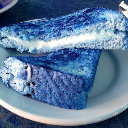

In [47]:
output_predictions = []

sel_idx = 1872
for idx, (data_i_x, data_i_y) in enumerate(mkdataset2.valid_dataset):
  pred_i = np.argmax(learner.model(data_i_x).numpy()[0])
  output_predictions.append(pred_i)
  if idx==sel_idx:
    tmp_img = data_i_x.numpy()[0]

cv2_imshow(tmp_img)

In [48]:
#將結果寫入 csv 檔
with open("predict_2dwideanddeep.csv", 'w') as fw:
  fw.write('Id,Category\n')
  for i, y in enumerate(output_predictions):
    fw.write('{},{}\n'.format(i, y))

In [49]:
!cat predict_2dwideanddeep.csv | head -100

Id,Category
0,0
1,10
2,10
3,9
4,7
5,3
6,4
7,10
8,2
9,2
10,2
11,8
12,0
13,10
14,0
15,4
16,9
17,4
18,2
19,9
20,3
21,5
22,1
23,3
24,9
25,3
26,2
27,4
28,2
29,8
30,5
31,9
32,2
33,1
34,2
35,9
36,2
37,10
38,10
39,2
40,6
41,2
42,8
43,2
44,5
45,1
46,10
47,3
48,8
49,9
50,10
51,1
52,3
53,3
54,4
55,8
56,2
57,9
58,6
59,3
60,5
61,4
62,2
63,3
64,10
65,8
66,8
67,9
68,9
69,10
70,2
71,5
72,5
73,8
74,9
75,7
76,4
77,2
78,9
79,9
80,4
81,2
82,9
83,8
84,8
85,9
86,4
87,4
88,1
89,9
90,8
91,4
92,4
93,9
94,0
95,6
96,1
97,2
98,6


In [52]:
files.download('predict_2dwideanddeep.csv') #0.74775 #private: 0.73894

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:
load_model = tf.keras.models.load_model("drive/My Drive/Colab Notebooks/CNNModel_2DWideAndDeep_3rd120/model_fulldataset.tf")

In [64]:
list_shapes1 = []
for ith_weight in load_model.get_weights():
  list_shapes1.append(ith_weight.shape)

list_shapes2 = []
for ith_weight in learner.model.get_weights():
  list_shapes2.append(ith_weight.shape)

print(str(list_shapes1))
list_shapes1 == list_shapes2

[(4, 4, 3, 64), (64,), (64,), (64,), (64,), (64,), (4, 4, 64, 128), (128,), (128,), (128,), (128,), (128,), (4, 4, 128, 256), (256,), (256,), (256,), (256,), (256,), (32, 32, 3, 32), (32,), (32,), (32,), (32,), (32,), (16, 16, 3, 64), (64,), (64,), (64,), (64,), (64,), (256, 256), (256,), (256, 128), (128,), (18432, 16), (16,), (16, 8), (8,), (50176, 64), (64,), (64, 16), (16,), (152, 11), (11,)]


True

In [65]:
load_model.get_weights()[0]

array([[[[-7.90541694e-02,  3.73482779e-02,  4.04442288e-02, ...,
           4.35428461e-03, -1.77183934e-02,  8.61328617e-02],
         [ 3.88446338e-02, -7.44623272e-03,  1.00550503e-02, ...,
          -3.32540385e-02,  2.95933355e-02,  7.07524940e-02],
         [ 1.57604665e-02, -3.22785713e-02, -3.06273624e-03, ...,
          -8.86848196e-02, -5.06492145e-03,  1.28799558e-01]],

        [[ 2.91758720e-02, -8.50567073e-02,  3.08194477e-02, ...,
           2.21323445e-02,  4.42955717e-02, -3.74681018e-02],
         [ 2.11983342e-02,  8.17704126e-02, -9.07741766e-03, ...,
          -1.15937002e-01,  6.85484987e-03, -2.91635394e-02],
         [-2.48346888e-02,  4.72637117e-02,  6.77250326e-02, ...,
          -5.12008853e-02, -1.38841588e-02,  3.92624028e-02]],

        [[-3.56495008e-02, -5.03670387e-02, -2.22640187e-02, ...,
          -4.05590460e-02, -7.93161392e-02,  2.60472521e-02],
         [ 2.84742545e-02,  3.54883187e-02,  1.32020405e-02, ...,
          -8.12660679e-02, -5.3855

In [66]:
learner.model.get_weights()[0]

array([[[[-7.90541694e-02,  3.73482779e-02,  4.04442288e-02, ...,
           4.35428461e-03, -1.77183934e-02,  8.61328617e-02],
         [ 3.88446338e-02, -7.44623272e-03,  1.00550503e-02, ...,
          -3.32540385e-02,  2.95933355e-02,  7.07524940e-02],
         [ 1.57604665e-02, -3.22785713e-02, -3.06273624e-03, ...,
          -8.86848196e-02, -5.06492145e-03,  1.28799558e-01]],

        [[ 2.91758720e-02, -8.50567073e-02,  3.08194477e-02, ...,
           2.21323445e-02,  4.42955717e-02, -3.74681018e-02],
         [ 2.11983342e-02,  8.17704126e-02, -9.07741766e-03, ...,
          -1.15937002e-01,  6.85484987e-03, -2.91635394e-02],
         [-2.48346888e-02,  4.72637117e-02,  6.77250326e-02, ...,
          -5.12008853e-02, -1.38841588e-02,  3.92624028e-02]],

        [[-3.56495008e-02, -5.03670387e-02, -2.22640187e-02, ...,
          -4.05590460e-02, -7.93161392e-02,  2.60472521e-02],
         [ 2.84742545e-02,  3.54883187e-02,  1.32020405e-02, ...,
          -8.12660679e-02, -5.3855